
# Bank Customer Churn Analysis
## Exploratory Data Analysis (EDA)

### Project Objective
Analyze customer demographics, banking behavior, and account characteristics to identify patterns associated with customer churn.

### Business Questions
1. What is the overall customer churn rate?
2. Which countries have higher churn rates?
3. How does customer age relate to churn?
4. Does customer activity affect churn?
5. How does product ownership relate to churn?
6. What relationships exist among numerical features?
7. Which customer segments show elevated churn?

### Tools
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Jupyter Notebook (VS Code)

In [ ]:

# ==================================================
# PROJECT : Bank Customer Churn Analysis
# PHASE: Exploratory Data Analysis
# STEP 1: Import Required Libraries
# ==================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

print("EDA libraries imported successfully!")


EDA libraries imported successfully!



## 1. Load and Validate the Cleaned Dataset

### Objective
Load the cleaned customer churn dataset and verify its structure, data types, completeness, and target variable before performing EDA.

### Validation Checks
- Confirm total rows and columns.
- Preview customer records.
- Review column names and data types.
- Check missing values.
- Check duplicate customer IDs.
- Verify the distribution of the churn target (`Exited`).

In [5]:
# ==================================================
# STEP 2.1: Load Cleaned Bank Churn Dataset
# ==================================================

from pathlib import Path


possible_paths = [
    Path("Data/Cleaned/bank_churn_clean.csv"),
    Path("../Data/Cleaned/bank_churn_clean.csv")
]

file_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if file_path is None:
    raise FileNotFoundError(
        "Cleaned dataset not found. Check the Data/Cleaned folder."
    )

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (10000, 13)


,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,EstimatedSalary,Balance,NumOfProducts,HasCrCard,IsActiveMember,Exited
0,15634602,Hargrave,619,France,Female,42,2,101348.88,0.00,1,1,1,1
1,15647311,Hill,608,Spain,Female,41,1,112542.58,83807.86,1,0,1,0
2,15619304,Onio,502,France,Female,42,8,113931.57,159660.80,3,1,0,1
3,15701354,Boni,699,France,Female,39,1,93826.63,0.00,2,0,0,0
4,15737888,Mitchell,850,Spain,Female,43,2,79084.10,125510.82,1,1,1,0


In [6]:
# ==================================================
# STEP 2.2: Dataset Validation
# ==================================================

# Standardize column names for analysis
df.columns = df.columns.str.strip().str.lower()

print("Column Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Customer IDs:")
print(df["customerid"].duplicated().sum())

print("\nChurn Distribution:")
print(df["exited"].value_counts().sort_index())

print("\nChurn Rate (%):")
print(round(df["exited"].mean() * 100, 2))

Column Names:
['customerid', 'surname', 'creditscore', 'geography', 'gender', 'age', 'tenure', 'estimatedsalary', 'balance', 'numofproducts', 'hascrcard', 'isactivemember', 'exited']

Data Types:
customerid           int64
surname                str
creditscore          int64
geography              str
gender                 str
age                  int64
tenure               int64
estimatedsalary    float64
balance            float64
numofproducts        int64
hascrcard            int64
isactivemember       int64
exited               int64
dtype: object

Missing Values:
customerid         0
surname            0
creditscore        0
geography          0
gender             0
age                0
tenure             0
estimatedsalary    0
balance            0
numofproducts      0
hascrcard          0
isactivemember     0
exited             0
dtype: int64

Duplicate Customer IDs:
0

Churn Distribution:
exited
0    7963
1    2037
Name: count, dtype: int64

Churn Rate (%):
20.37



### Data Validation Summary

**Key Findings**
- The cleaned dataset contains 10,000 customer records.
- Customer IDs are unique.
- No missing values were identified.
- The target variable `exited` is binary:
  - `0` = Retained customer
  - `1` = Churned customer
- The overall customer churn rate is 20.37%.

**Business Interpretation**

Approximately one in five customers in this dataset has churned. This establishes the baseline against which we will compare churn rates across customer segments.

**Next Analysis**

Perform descriptive statistical analysis to understand the distribution of numerical and categorical customer attributes.


In [7]:
# ==================================================
# STEP 3.1: Descriptive Statistics
# ==================================================

numerical_columns = [
    "creditscore",
    "age",
    "tenure",
    "balance",
    "numofproducts",
    "estimatedsalary"
]

summary_stats = df[numerical_columns].describe().T

display(summary_stats)

,count,mean,std,min,25%,50%,75%,max
creditscore,10000.00,650.53,96.65,350.00,584.00,652.00,718.00,850.00
age,10000.00,38.92,10.49,18.00,32.00,37.00,44.00,92.00
tenure,10000.00,5.01,2.89,0.00,3.00,5.00,7.00,10.00
balance,10000.00,76485.89,62397.41,0.00,0.00,97198.54,127644.24,250898.09
numofproducts,10000.00,1.53,0.58,1.00,1.00,1.00,2.00,4.00
estimatedsalary,10000.00,100090.24,57510.49,11.58,51002.11,100193.91,149388.25,199992.48


In [9]:
# ==================================================
# STEP 3.2: Compare Retained vs Churned Customers
# ==================================================

churn_comparison = (
    df.groupby("exited")[numerical_columns]
    .agg(["mean", "median", "std"])
    .round(2)
)

display(churn_comparison)

creditscore                 age              tenure              \
              mean median    std  mean median   std   mean median  std   
exited                                                                   
0           651.85 653.00  95.65 37.41  36.00 10.13   5.03   5.00 2.88   
1           645.35 646.00 100.32 44.84  45.00  9.76   4.93   5.00 2.94   

        balance                    numofproducts             estimatedsalary  \
           mean    median      std          mean median  std            mean   
exited                                                                         
0      72745.30  92072.68 62848.04          1.54   2.00 0.51        99738.39   
1      91108.54 109349.29 58360.79          1.48   1.00 0.80       101465.68   

                           
          median      std  
exited                     
0       99645.04 57405.59  
1      102460.84 57912.42


## 3. Customer Churn Distribution

### Business Question
What is the overall customer churn distribution?

### Objective
Analyze the proportion of retained and churned customers to establish the baseline churn rate.

### Visualizations
1. Customer churn count plot
2. Customer churn percentage donut chart

### Key Metrics
- Total customers
- Retained customers
- Churned customers
- Customer churn rate
- Customer retention rate


In [10]:
# ==================================================
# STEP 4.1: Overall Customer Churn Metrics
# ==================================================

total_customers = len(df)

churned_customers = (df["exited"] == 1).sum()
retained_customers = (df["exited"] == 0).sum()

churn_rate = churned_customers / total_customers * 100
retention_rate = retained_customers / total_customers * 100

print(f"Total Customers: {total_customers:,}")
print(f"Retained Customers: {retained_customers:,}")
print(f"Churned Customers: {churned_customers:,}")
print(f"Churn Rate: {churn_rate:.2f}%")
print(f"Retention Rate: {retention_rate:.2f}%")

Total Customers: 10,000
Retained Customers: 7,963
Churned Customers: 2,037
Churn Rate: 20.37%
Retention Rate: 79.63%


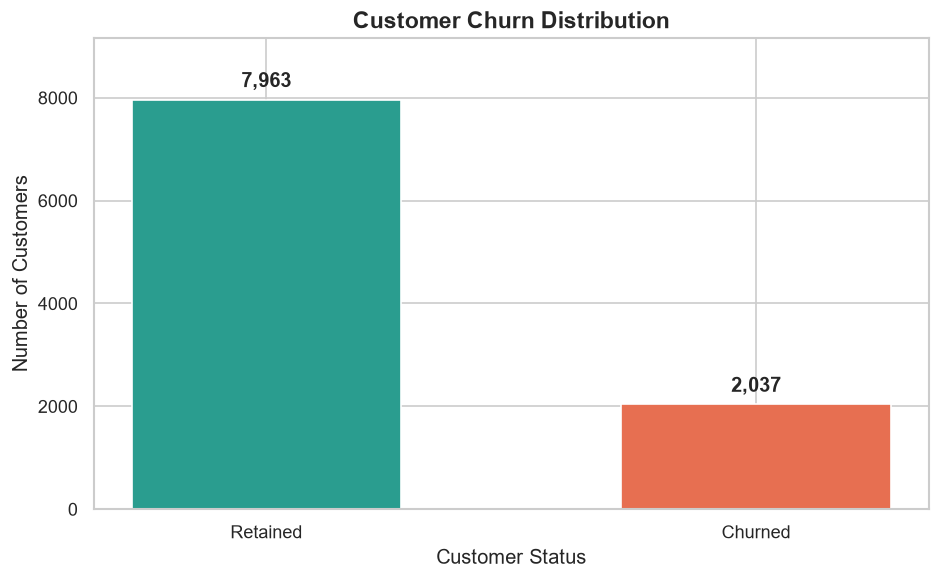

In [54]:
# ==================================================
# STEP 4.2: Customer Churn Count Plot
# ==================================================

# Create visualization output directory
from pathlib import Path

# Handle notebooks executed from Python folder or project root
if Path("../Data").exists():
    output_dir = Path("Visualizations")
else:
    output_dir = Path("Python/Visualizations")

output_dir.mkdir(parents=True, exist_ok=True)

# Prepare chart data
churn_counts = df["exited"].value_counts().reindex([0, 1])

labels = ["Retained", "Churned"]
colors = ["#2A9D8F", "#E76F51"]

# Create chart
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(labels, churn_counts.values, color=colors, width=0.55)

# Add count labels
for bar in bars:
    height = bar.get_height()

    ax.annotate(
        f"{height:,.0f}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

ax.set_title("Customer Churn Distribution", fontsize=14, fontweight="bold")
ax.set_xlabel("Customer Status")
ax.set_ylabel("Number of Customers")
ax.set_ylim(0, churn_counts.max() * 1.15)

plt.tight_layout()

# Export image before displaying
plt.savefig(
    output_dir / "churn_count_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

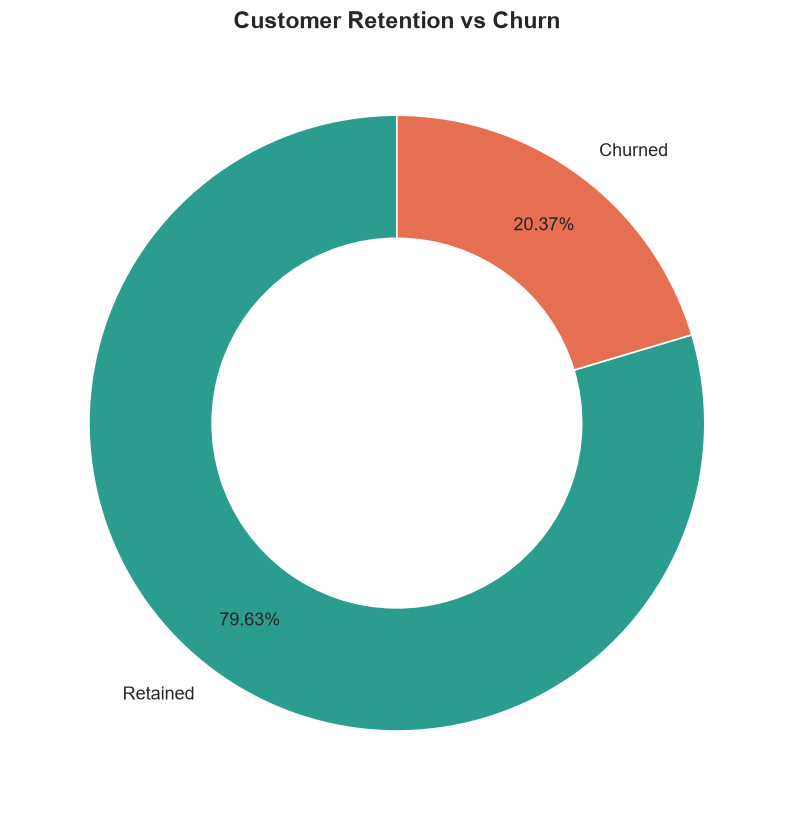

In [12]:
# ==================================================
# STEP 4.3: Customer Churn Donut Chart
# ==================================================

fig, ax = plt.subplots(figsize=(7, 7))

ax.pie(
    [retained_customers, churned_customers],
    labels=["Retained", "Churned"],
    colors=["#2A9D8F", "#E76F51"],
    autopct="%1.2f%%",
    startangle=90,
    pctdistance=0.8,
    wedgeprops={"width": 0.4, "edgecolor": "white"},
    textprops={"fontsize": 11}
)

ax.set_title(
    "Customer Retention vs Churn",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    output_dir / "churn_donut_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Customer Churn Distribution — Business Findings

#### Key Findings
- Total customers analyzed: 10,000.
- Retained customers: 7,963 (79.63%).
- Churned customers: 2,037 (20.37%).
- Approximately one in five customers has churned.

#### Business Insights
- The overall churn rate of 20.37% establishes the baseline for customer retention analysis.
- Retained customers represent the majority of the dataset.
- Churned customers form a smaller but substantial group that warrants further investigation.

#### Business Recommendations
- Investigate which customer segments have churn rates above the overall baseline.
- Examine customer activity, geography, age, and product ownership to identify elevated-churn segments.
- Use the baseline churn rate to compare segment-level performance.


## 4. Geography vs Customer Churn

### Business Question
Which countries have the highest customer churn rates?

### Objective
Compare customer counts, churned customers, and churn rates across different geographical regions.

### Visualizations
1. Customer distribution by geography
2. Customer churn rate by geography

### Key Metrics
- Total customers by country
- Churned customers by country
- Churn rate (%)
- Overall churn benchmark (20.37%)


In [13]:
# ==================================================
# STEP 5.1: Geography-Based Churn Analysis
# ==================================================

geography_analysis = (
    df.groupby("geography")
    .agg(
        total_customers=("customerid", "count"),
        churned_customers=("exited", "sum")
    )
    .reset_index()
)

geography_analysis["retained_customers"] = (
    geography_analysis["total_customers"]
    - geography_analysis["churned_customers"]
)

geography_analysis["churn_rate"] = (
    geography_analysis["churned_customers"]
    / geography_analysis["total_customers"] * 100
)

geography_analysis = geography_analysis.sort_values(
    "churn_rate", ascending=False
)

display(geography_analysis.round(2))

,geography,total_customers,churned_customers,retained_customers,churn_rate
1,Germany,2509,814,1695,32.44
2,Spain,2477,413,2064,16.67
0,France,5014,810,4204,16.15


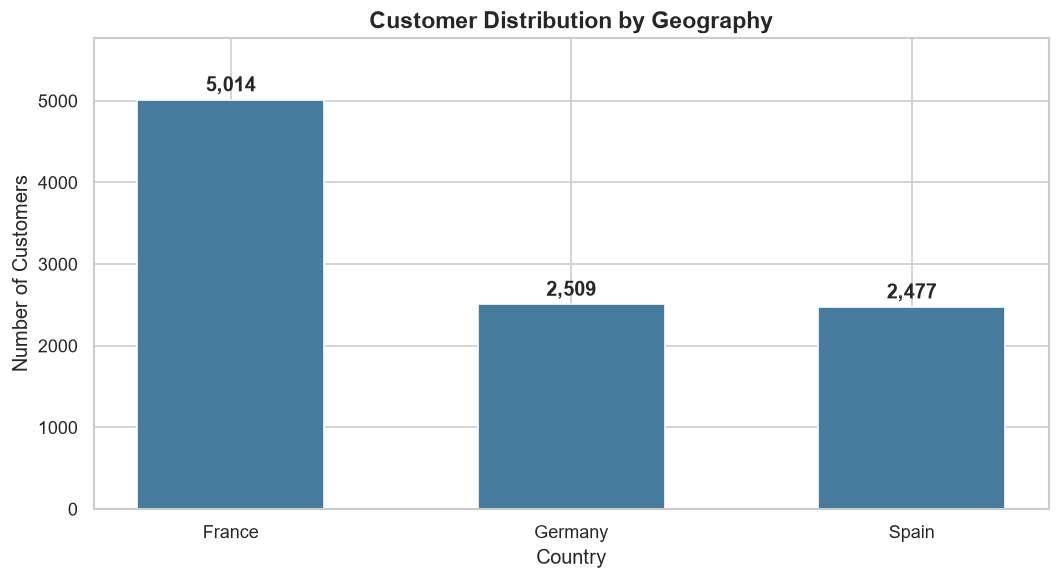

In [14]:
# ==================================================
# STEP 5.2: Customer Distribution by Geography
# ==================================================

fig, ax = plt.subplots(figsize=(9, 5))

customer_counts = geography_analysis.sort_values(
    "total_customers", ascending=False
)

bars = ax.bar(
    customer_counts["geography"],
    customer_counts["total_customers"],
    color="#457B9D",
    width=0.55
)

for bar in bars:
    height = bar.get_height()

    ax.annotate(
        f"{height:,.0f}",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontweight="bold"
    )

ax.set_title(
    "Customer Distribution by Geography",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Country")
ax.set_ylabel("Number of Customers")
ax.set_ylim(0, customer_counts["total_customers"].max() * 1.15)

plt.tight_layout()

plt.savefig(
    output_dir / "geography_customer_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

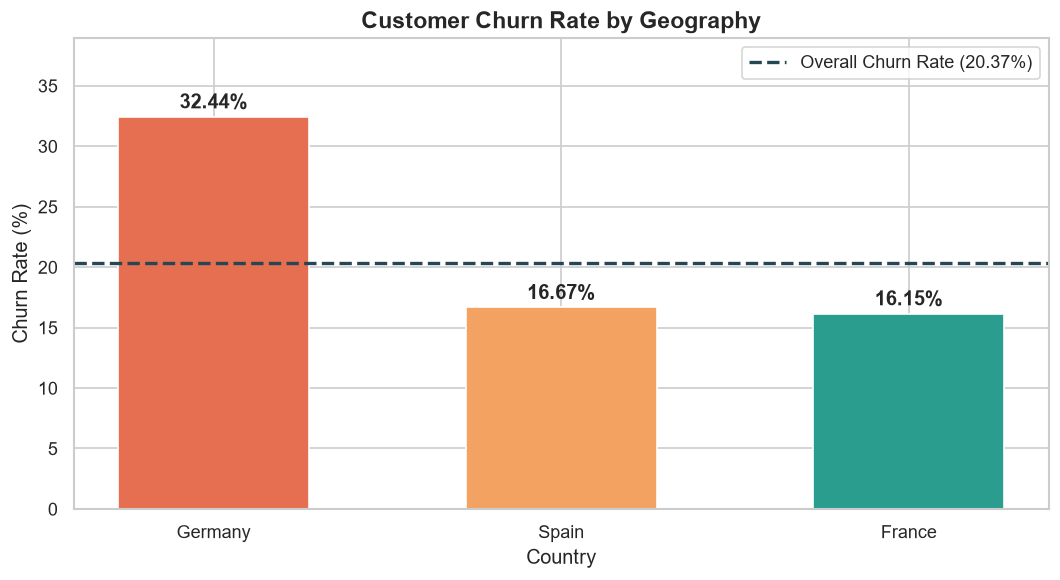

In [15]:
# ==================================================
# STEP 5.3: Customer Churn Rate by Geography
# ==================================================

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    geography_analysis["geography"],
    geography_analysis["churn_rate"],
    color=["#E76F51", "#F4A261", "#2A9D8F"],
    width=0.55
)

# Overall churn benchmark
ax.axhline(
    y=churn_rate,
    color="#264653",
    linestyle="--",
    linewidth=2,
    label=f"Overall Churn Rate ({churn_rate:.2f}%)"
)

for bar in bars:
    height = bar.get_height()

    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontweight="bold"
    )

ax.set_title(
    "Customer Churn Rate by Geography",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Country")
ax.set_ylabel("Churn Rate (%)")
ax.set_ylim(0, geography_analysis["churn_rate"].max() * 1.2)
ax.legend()

plt.tight_layout()

plt.savefig(
    output_dir / "geography_churn_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Geography Analysis — Business Findings

#### Key Findings
- Germany has the highest customer churn rate at 32.44%, with 814 churned customers out of 2,509.
- Spain has a churn rate of 16.67%, with 413 churned customers.
- France has a churn rate of 16.15%, with 810 churned customers.
- Germany's churn rate is approximately 12.07 percentage points above the overall churn benchmark of 20.37%.
- France has the largest customer base, with 5,014 customers.

#### Business Insights
- Germany shows substantially higher churn than the other two countries.
- France and Germany have similar numbers of churned customers, despite France having approximately twice as many customers.
- Churn rate and churn volume provide different perspectives and should both be considered when evaluating retention priorities.

#### Business Recommendations
- Investigate customer activity, product ownership, and age distributions within Germany.
- Compare Germany's customer characteristics with France and Spain to identify potential explanations for the observed differences.
- Prioritize further investigation of Germany without assuming geography itself causes churn.


## 5. Gender and Age vs Customer Churn

### Business Questions
1. How does customer churn differ by gender?
2. Which age groups have higher churn rates?
3. How do age distributions differ between retained and churned customers?

### Objectives
- Compare churn rates and volumes by gender.
- Analyze churn rates across customer age groups.
- Visualize the age distribution of retained and churned customers.
- Identify patterns for further investigation.

### Visualizations
1. Churn rate by gender — Bar chart
2. Churn rate by age group — Bar chart
3. Age distribution by churn status — Box plot

### Benchmark
Overall customer churn rate: 20.37%

In [16]:
# ==================================================
# STEP 6.1: Gender-Based Churn Analysis
# ==================================================

gender_analysis = (
    df.groupby("gender")
    .agg(
        total_customers=("customerid", "count"),
        churned_customers=("exited", "sum")
    )
    .reset_index()
)

gender_analysis["churn_rate"] = (
    gender_analysis["churned_customers"]
    / gender_analysis["total_customers"] * 100
)

gender_analysis = gender_analysis.sort_values(
    "churn_rate", ascending=False
)

display(gender_analysis.round(2))

,gender,total_customers,churned_customers,churn_rate
0,Female,4543,1139,25.07
1,Male,5457,898,16.46


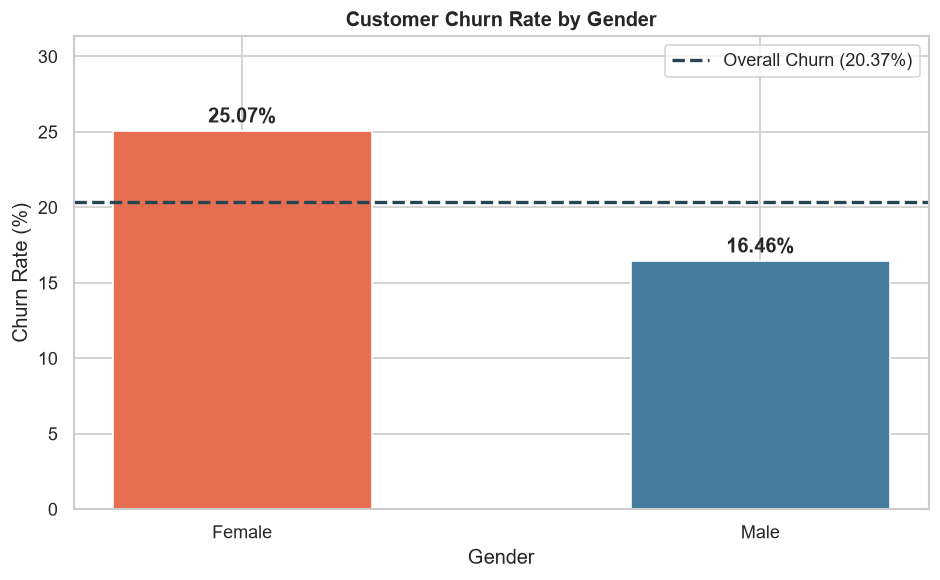

In [17]:
# ==================================================
# STEP 6.2: Gender-Based Churn Rate Visualization
# ==================================================

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    gender_analysis["gender"],
    gender_analysis["churn_rate"],
    color=["#E76F51", "#457B9D"],
    width=0.5
)

ax.axhline(
    churn_rate,
    color="#264653",
    linestyle="--",
    linewidth=2,
    label=f"Overall Churn ({churn_rate:.2f}%)"
)

for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontweight="bold"
    )

ax.set_title("Customer Churn Rate by Gender", fontweight="bold")
ax.set_xlabel("Gender")
ax.set_ylabel("Churn Rate (%)")
ax.set_ylim(0, gender_analysis["churn_rate"].max() * 1.25)
ax.legend()

plt.tight_layout()

plt.savefig(
    output_dir / "gender_churn_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Age Group Analysis

**Business Question:** Which customer age groups have the highest churn rates?

We will divide customers into five age groups:

- 18–30
- 31–40
- 41–50
- 51–60
- 61+

These categories allow us to compare customer counts, churn volumes, and churn rates across age ranges.


In [18]:
# ==================================================
# STEP 6.3: Age Group-Based Churn Analysis
# ==================================================

age_bins = [17, 30, 40, 50, 60, np.inf]
age_labels = ["18-30", "31-40", "41-50", "51-60", "61+"]

df["age_group"] = pd.cut(
    df["age"],
    bins=age_bins,
    labels=age_labels
)

age_analysis = (
    df.groupby("age_group", observed=True)
    .agg(
        total_customers=("customerid", "count"),
        churned_customers=("exited", "sum")
    )
    .reset_index()
)

age_analysis["churn_rate"] = (
    age_analysis["churned_customers"]
    / age_analysis["total_customers"] * 100
)

display(age_analysis.round(2))

,age_group,total_customers,churned_customers,churn_rate
0,18-30,1968,148,7.52
1,31-40,4451,538,12.09
2,41-50,2320,788,33.97
3,51-60,797,448,56.21
4,61+,464,115,24.78


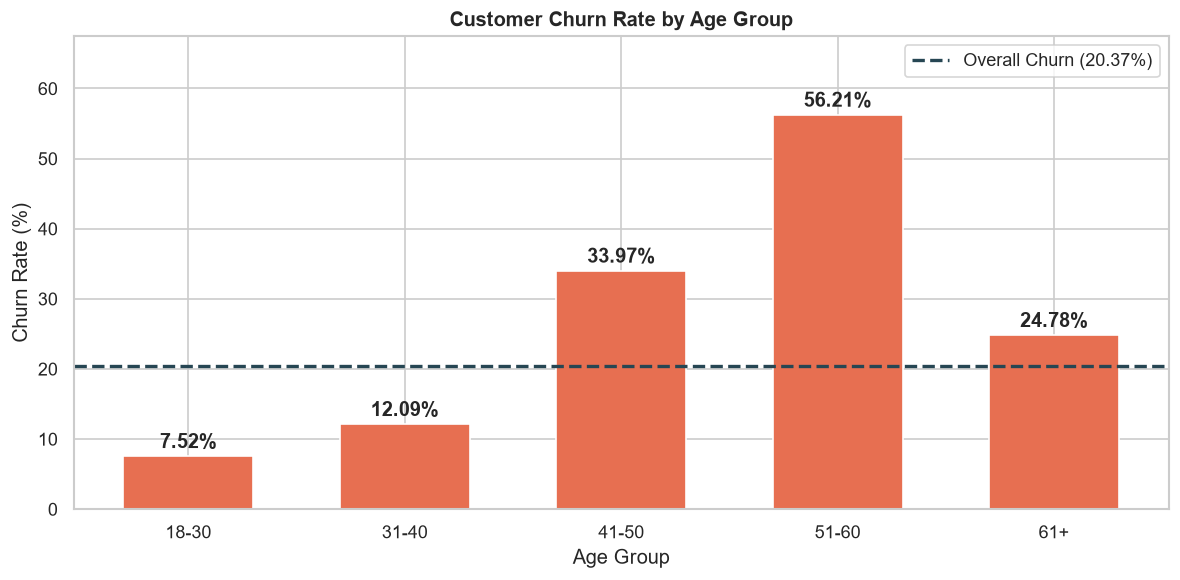

In [19]:
# ==================================================
# STEP 6.4: Churn Rate by Age Group
# ==================================================

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    age_analysis["age_group"].astype(str),
    age_analysis["churn_rate"],
    color="#E76F51",
    width=0.6
)

ax.axhline(
    churn_rate,
    color="#264653",
    linestyle="--",
    linewidth=2,
    label=f"Overall Churn ({churn_rate:.2f}%)"
)

for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontweight="bold"
    )

ax.set_title("Customer Churn Rate by Age Group", fontweight="bold")
ax.set_xlabel("Age Group")
ax.set_ylabel("Churn Rate (%)")
ax.set_ylim(0, age_analysis["churn_rate"].max() * 1.2)
ax.legend()

plt.tight_layout()

plt.savefig(
    output_dir / "age_group_churn_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

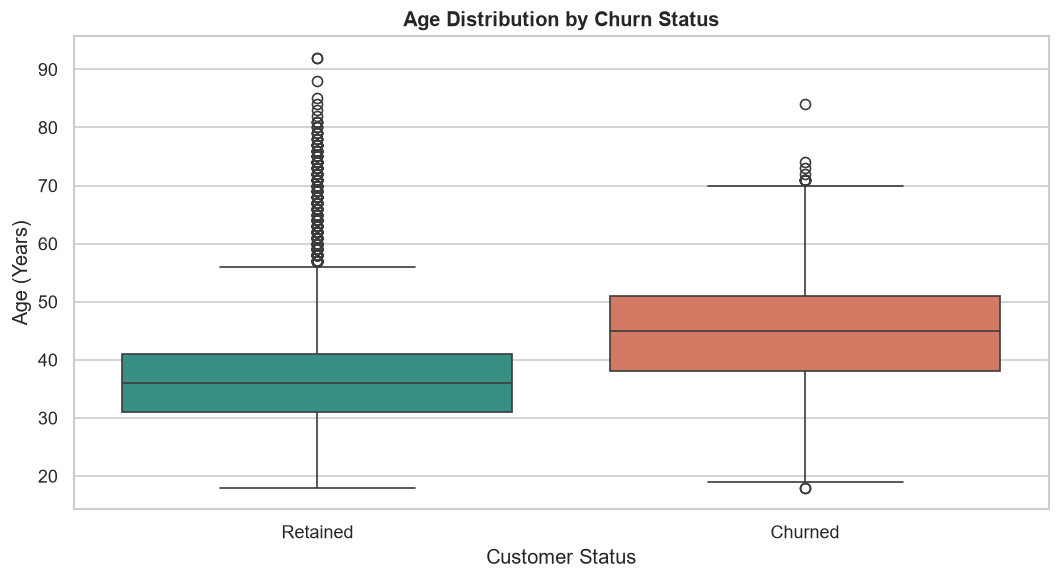

In [20]:
# ==================================================
# STEP 6.5: Age Distribution by Churn Status
# ==================================================

fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="exited",
    y="age",
    order=[0, 1],
    hue="exited",
    palette={0: "#2A9D8F", 1: "#E76F51"},
    legend=False,
    ax=ax
)

ax.set_xticks([0, 1])
ax.set_xticklabels(["Retained", "Churned"])

ax.set_title("Age Distribution by Churn Status", fontweight="bold")
ax.set_xlabel("Customer Status")
ax.set_ylabel("Age (Years)")

plt.tight_layout()

plt.savefig(
    output_dir / "age_distribution_by_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Gender and Age Analysis — Business Findings

#### Key Findings

**Gender**
- Female customers have a churn rate of 25.07%.
- Male customers have a churn rate of 16.46%.
- The observed difference is 8.61 percentage points.

**Age**
- Customers aged 51–60 have the highest churn rate at 56.21%.
- Customers aged 41–50 have a churn rate of 33.97%.
- Customers aged 18–30 have the lowest churn rate at 7.52%.
- Customers aged 41–50 contribute the highest churn volume, with 788 churned customers.
- Churned customers have a median age of 45, compared with 36 for retained customers.

#### Business Insights
- Age shows a notable association with customer churn.
- High churn rate and high churn volume are not necessarily concentrated in the same age group.
- Gender-level differences are descriptive and may be influenced by other customer characteristics.

#### Business Recommendations
- Investigate account activity, product ownership, and geography alongside age.
- Analyze the customer experience across different customer segments.
- Avoid using age or gender alone to determine individual retention treatment or eligibility.


## 6. Customer Banking Behavior Analysis

### Business Questions
1. Do inactive customers have higher churn rates?
2. How does the number of banking products relate to churn?
3. Which combinations of customer activity and product ownership show elevated churn?

### Objectives
- Compare churn rates for active and inactive customers.
- Analyze churn rates by number of banking products.
- Investigate the combined relationship between activity, product ownership, and churn.

### Visualizations
1. Churn rate by customer activity — Bar chart
2. Churn rate by number of products — Bar chart
3. Activity vs. product ownership — Heatmap

### Benchmark
Overall customer churn rate: 20.37%


In [22]:
# ==================================================
# STEP 7.1: Customer Activity Analysis
# ==================================================

activity_analysis = (
    df.groupby("isactivemember")
    .agg(
        total_customers=("customerid", "count"),
        churned_customers=("exited", "sum")
    )
    .reset_index()
)

activity_analysis["churn_rate"] = (
    activity_analysis["churned_customers"]
    / activity_analysis["total_customers"] * 100
)

activity_analysis["activity_status"] = (
    activity_analysis["isactivemember"]
    .map({0: "Inactive", 1: "Active"})
)

display(activity_analysis.round(2))

,isactivemember,total_customers,churned_customers,churn_rate,activity_status
0,0,4849,1302,26.85,Inactive
1,1,5151,735,14.27,Active


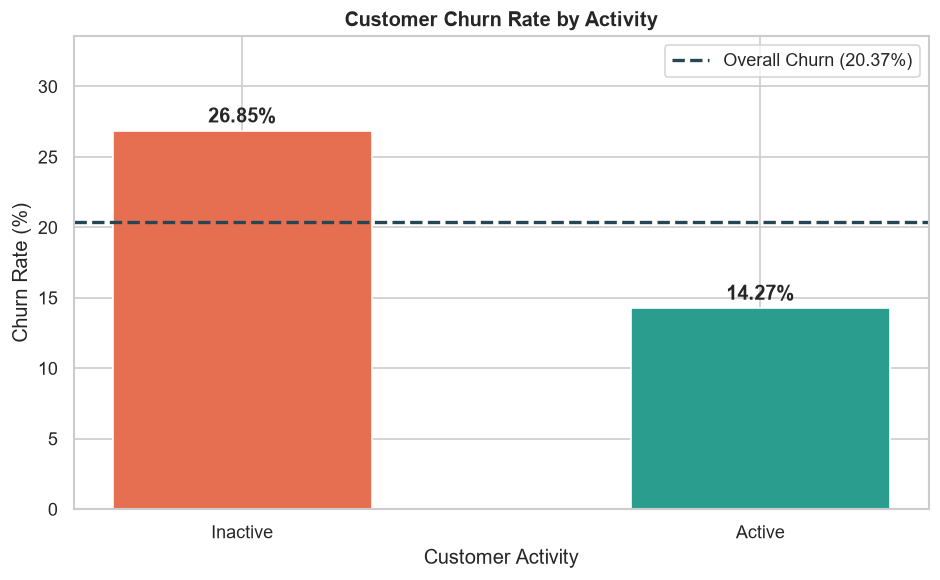

In [23]:
# ==================================================
# STEP 7.2: Churn Rate by Customer Activity
# ==================================================

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    activity_analysis["activity_status"],
    activity_analysis["churn_rate"],
    color=["#E76F51", "#2A9D8F"],
    width=0.5
)

ax.axhline(
    churn_rate,
    color="#264653",
    linestyle="--",
    linewidth=2,
    label=f"Overall Churn ({churn_rate:.2f}%)"
)

for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontweight="bold"
    )

ax.set_title("Customer Churn Rate by Activity", fontweight="bold")
ax.set_xlabel("Customer Activity")
ax.set_ylabel("Churn Rate (%)")
ax.set_ylim(0, activity_analysis["churn_rate"].max() * 1.25)
ax.legend()

plt.tight_layout()

plt.savefig(
    output_dir / "activity_churn_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Product Ownership Analysis

**Business Question:** How does the number of banking products relate to customer churn?

We will compare customers owning 1, 2, 3, or 4 banking products.

Both churn rates and customer counts will be considered because smaller customer groups can produce extreme percentages.


In [24]:
# ==================================================
# STEP 7.3: Product Ownership Analysis
# ==================================================

product_analysis = (
    df.groupby("numofproducts")
    .agg(
        total_customers=("customerid", "count"),
        churned_customers=("exited", "sum")
    )
    .reset_index()
)

product_analysis["churn_rate"] = (
    product_analysis["churned_customers"]
    / product_analysis["total_customers"] * 100
)

display(product_analysis.round(2))

,numofproducts,total_customers,churned_customers,churn_rate
0,1,5084,1409,27.71
1,2,4590,348,7.58
2,3,266,220,82.71
3,4,60,60,100.00


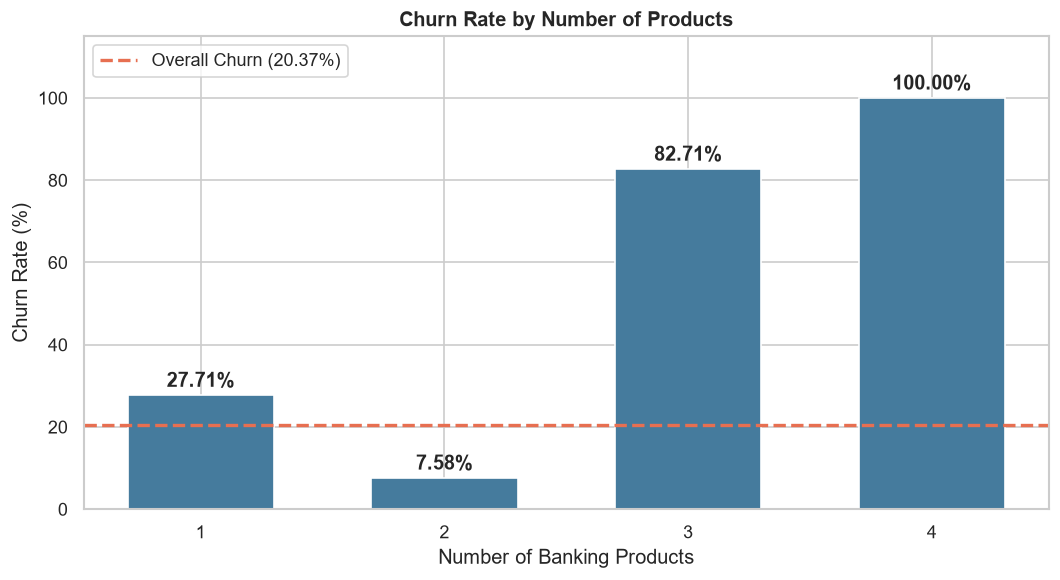

In [25]:
# ==================================================
# STEP 7.4: Churn Rate by Number of Products
# ==================================================

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    product_analysis["numofproducts"].astype(str),
    product_analysis["churn_rate"],
    color="#457B9D",
    width=0.6
)

ax.axhline(
    churn_rate,
    color="#E76F51",
    linestyle="--",
    linewidth=2,
    label=f"Overall Churn ({churn_rate:.2f}%)"
)

for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontweight="bold"
    )

ax.set_title("Churn Rate by Number of Products", fontweight="bold")
ax.set_xlabel("Number of Banking Products")
ax.set_ylabel("Churn Rate (%)")
ax.set_ylim(0, 115)
ax.legend()

plt.tight_layout()

plt.savefig(
    output_dir / "product_ownership_churn_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [26]:
# ==================================================
# STEP 7.5: Activity and Product Ownership Analysis
# ==================================================

activity_product_analysis = (
    df.groupby(["isactivemember", "numofproducts"])
    .agg(
        total_customers=("customerid", "count"),
        churned_customers=("exited", "sum")
    )
    .reset_index()
)

activity_product_analysis["churn_rate"] = (
    activity_product_analysis["churned_customers"]
    / activity_product_analysis["total_customers"] * 100
)

activity_product_analysis["activity_status"] = (
    activity_product_analysis["isactivemember"]
    .map({0: "Inactive", 1: "Active"})
)

display(activity_product_analysis.round(2))

,isactivemember,numofproducts,total_customers,churned_customers,churn_rate,activity_status
0,0,1,2521,924,36.65,Inactive
1,0,2,2144,212,9.89,Inactive
2,0,3,153,135,88.24,Inactive
3,0,4,31,31,100.00,Inactive
4,1,1,2563,485,18.92,Active
5,1,2,2446,136,5.56,Active
6,1,3,113,85,75.22,Active
7,1,4,29,29,100.00,Active


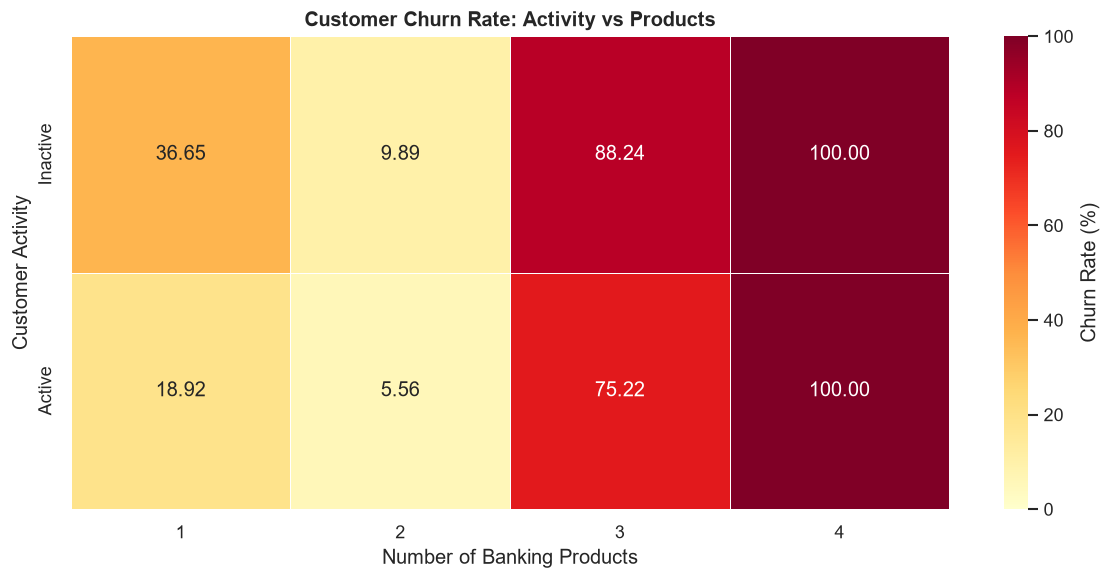

In [27]:
# ==================================================
# STEP 7.6: Activity × Product Churn Heatmap
# ==================================================

heatmap_data = activity_product_analysis.pivot(
    index="activity_status",
    columns="numofproducts",
    values="churn_rate"
)

heatmap_data = heatmap_data.reindex(["Inactive", "Active"])

fig, ax = plt.subplots(figsize=(10, 5))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Churn Rate (%)"},
    ax=ax
)

ax.set_title(
    "Customer Churn Rate: Activity vs Products",
    fontweight="bold"
)
ax.set_xlabel("Number of Banking Products")
ax.set_ylabel("Customer Activity")

plt.tight_layout()

plt.savefig(
    output_dir / "activity_product_churn_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Banking Behavior Analysis — Business Findings

#### Key Findings

**Customer Activity**
- Inactive customers have a churn rate of 26.85%.
- Active customers have a churn rate of 14.27%.
- Inactive customers show a 12.58 percentage-point higher churn rate.

**Product Ownership**
- Customers with one product have a churn rate of 27.71%.
- Customers with two products have the lowest churn rate at 7.58%.
- Customers with three products have a churn rate of 82.71%.
- All 60 customers with four products churned in this dataset.

**Combined Analysis**
- Inactive customers with one product have a churn rate of 36.65%.
- Active customers with one product have a churn rate of 18.92%.
- Inactive customers with two products have a churn rate of 9.89%.
- Active customers with two products have a churn rate of 5.56%.

#### Business Insights
- Customer inactivity is associated with higher churn.
- Product ownership shows a non-linear relationship with churn.
- Inactive, single-product customers represent an important segment for further investigation.
- The three-product and four-product segments have relatively small customer counts, so their extreme churn rates require cautious interpretation.

#### Business Recommendations
- Investigate engagement patterns among inactive customers.
- Review the experience of customers holding a single banking product.
- Examine the characteristics of customers with three or four products before proposing interventions.
- Evaluate possible retention initiatives through controlled testing rather than assuming these characteristics cause churn.


## 7. Financial and Account Characteristics Analysis

### Business Questions
1. Do customers with higher account balances have different churn rates?
2. How does credit score relate to customer churn?
3. Does customer tenure show a relationship with churn?
4. Does estimated salary vary meaningfully between churned and retained customers?
5. Is credit card ownership associated with churn?

### Objectives
- Examine numerical distributions and differences by churn status.
- Compare churn rates across balance, credit score, tenure, and salary groups.
- Analyze churn rates by credit card ownership.
- Identify patterns that warrant further investigation.

### Visualizations
1. Account balance distribution by churn — Box plot
2. Churn rate by balance group — Bar chart
3. Churn rate by credit score group — Bar chart
4. Churn rate by tenure group — Bar chart
5. Churn rate by salary group — Bar chart
6. Churn rate by credit card ownership — Bar chart

### Benchmark
Overall customer churn rate: 20.37%


In [28]:
# ==================================================
# STEP 8.1: Create Financial and Account Segments
# ==================================================

df["balance_group"] = pd.cut(
    df["balance"],
    bins=[-0.01, 0, 50000, 100000, 150000, np.inf],
    labels=["Zero", "Below 50K", "50K-100K", "100K-150K", "150K+"],
    include_lowest=True
)

df["credit_score_group"] = pd.cut(
    df["creditscore"],
    bins=[-np.inf, 499, 599, 699, 799, np.inf],
    labels=["Below 500", "500-599", "600-699", "700-799", "800+"]
)

df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[-1, 2, 5, 8, 10],
    labels=["0-2", "3-5", "6-8", "9-10"]
)

df["salary_group"] = pd.cut(
    df["estimatedsalary"],
    bins=[-np.inf, 40000, 80000, 120000, 160000, np.inf],
    labels=["Below 40K", "40K-80K", "80K-120K", "120K-160K", "160K+"]
)

df["credit_card_status"] = df["hascrcard"].map({
    0: "No Credit Card",
    1: "Has Credit Card"
})

print("Financial and account segments created successfully!")

Financial and account segments created successfully!


In [29]:
# ==================================================
# STEP 8.2: Reusable Segment Churn Analysis
# ==================================================

def analyze_churn_by_segment(data, column):
    result = (
        data.groupby(column, observed=True)
        .agg(
            total_customers=("customerid", "count"),
            churned_customers=("exited", "sum")
        )
        .reset_index()
    )

    result["churn_rate"] = (
        result["churned_customers"]
        / result["total_customers"] * 100
    )

    return result


balance_analysis = analyze_churn_by_segment(df, "balance_group")
credit_analysis = analyze_churn_by_segment(df, "credit_score_group")
tenure_analysis = analyze_churn_by_segment(df, "tenure_group")
salary_analysis = analyze_churn_by_segment(df, "salary_group")
card_analysis = analyze_churn_by_segment(df, "credit_card_status")

print("Account Balance Analysis")
display(balance_analysis.round(2))

print("Credit Score Analysis")
display(credit_analysis.round(2))

print("Tenure Analysis")
display(tenure_analysis.round(2))

print("Estimated Salary Analysis")
display(salary_analysis.round(2))

print("Credit Card Ownership Analysis")
display(card_analysis.round(2))

Account Balance Analysis


,balance_group,total_customers,churned_customers,churn_rate
0,Zero,3617,500,13.82
1,Below 50K,75,26,34.67
2,50K-100K,1509,300,19.88
3,100K-150K,3830,987,25.77
4,150K+,969,224,23.12


Credit Score Analysis


,credit_score_group,total_customers,churned_customers,churn_rate
0,Below 500,632,150,23.73
1,500-599,2402,510,21.23
2,600-699,3818,753,19.72
3,700-799,2493,496,19.90
4,800+,655,128,19.54


Tenure Analysis


,tenure_group,total_customers,churned_customers,churn_rate
0,0-2,2496,528,21.15
1,3-5,3010,625,20.76
2,6-8,3020,570,18.87
3,9-10,1474,314,21.30


Estimated Salary Analysis


,salary_group,total_customers,churned_customers,churn_rate
0,Below 40K,1955,394,20.15
1,40K-80K,2033,403,19.82
2,80K-120K,2029,407,20.06
3,120K-160K,1989,402,20.21
4,160K+,1994,431,21.61


Credit Card Ownership Analysis


,credit_card_status,total_customers,churned_customers,churn_rate
0,Has Credit Card,7055,1424,20.18
1,No Credit Card,2945,613,20.81



### Visualization Method

For each customer characteristic, we will compare the segment-level churn rate with the overall churn benchmark of 20.37%.

A bar chart is appropriate for comparing churn rates across defined customer segments.

For account balance, a box plot will additionally show the median, spread, and potential outliers for retained and churned customers.

**Interpretation Note:** Differences between groups are descriptive associations and do not establish causation.


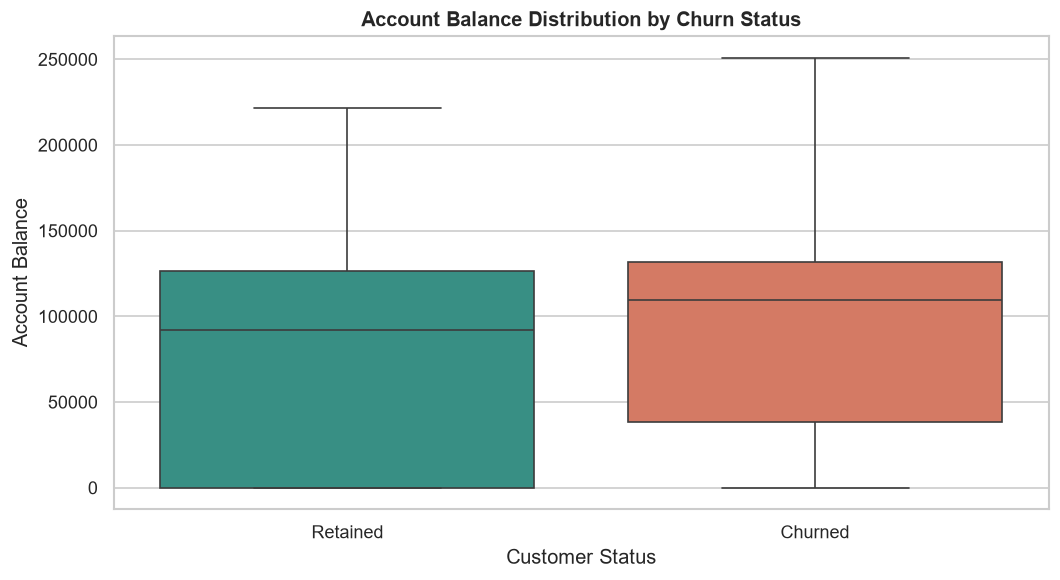

In [30]:
# ==================================================
# STEP 8.3: Account Balance Distribution by Churn
# ==================================================

fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="exited",
    y="balance",
    order=[0, 1],
    hue="exited",
    palette={0: "#2A9D8F", 1: "#E76F51"},
    legend=False,
    ax=ax
)

ax.set_xticks([0, 1])
ax.set_xticklabels(["Retained", "Churned"])

ax.set_title("Account Balance Distribution by Churn Status", fontweight="bold")
ax.set_xlabel("Customer Status")
ax.set_ylabel("Account Balance")

plt.tight_layout()

plt.savefig(
    output_dir / "balance_distribution_by_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [33]:
# ==================================================
# STEP 8.4: Reusable Churn Rate Visualization
# ==================================================

def plot_segment_churn(data, category, title, filename):
    fig, ax = plt.subplots(figsize=(10, 5))

    bars = ax.bar(
        data[category].astype(str),
        data["churn_rate"],
        color="#457B9D",
        width=0.6
    )

    ax.axhline(
        churn_rate,
        color="#E76F51",
        linestyle="--",
        linewidth=2,
        label=f"Overall Churn ({churn_rate:.2f}%)"
    )

    for bar in bars:
        height = bar.get_height()

        ax.annotate(
            f"{height:.2f}%",
            (bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontweight="bold"
        )

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel(category.replace("_", " ").title())
    ax.set_ylabel("Churn Rate (%)")
    ax.set_ylim(0, max(data["churn_rate"].max(), churn_rate) * 1.25)
    ax.legend()

    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()

    plt.savefig(
        output_dir / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

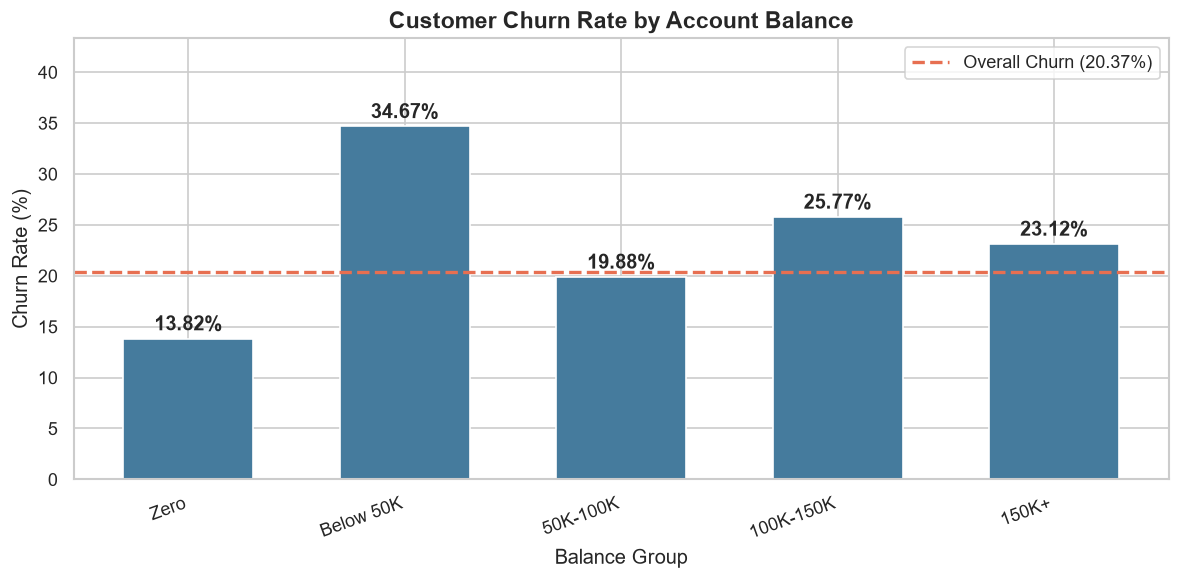

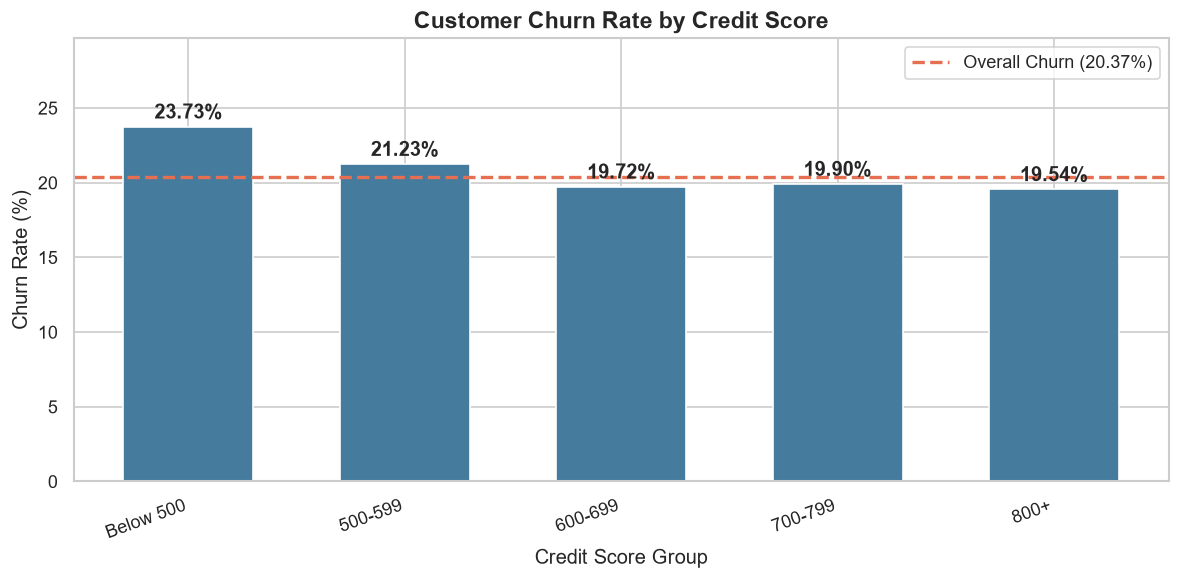

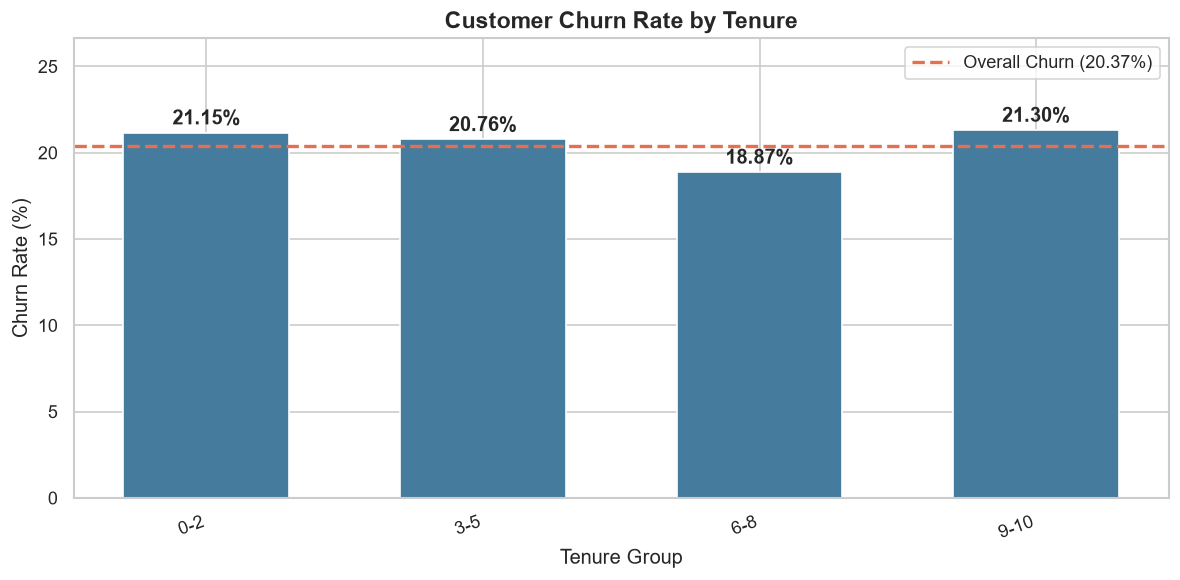

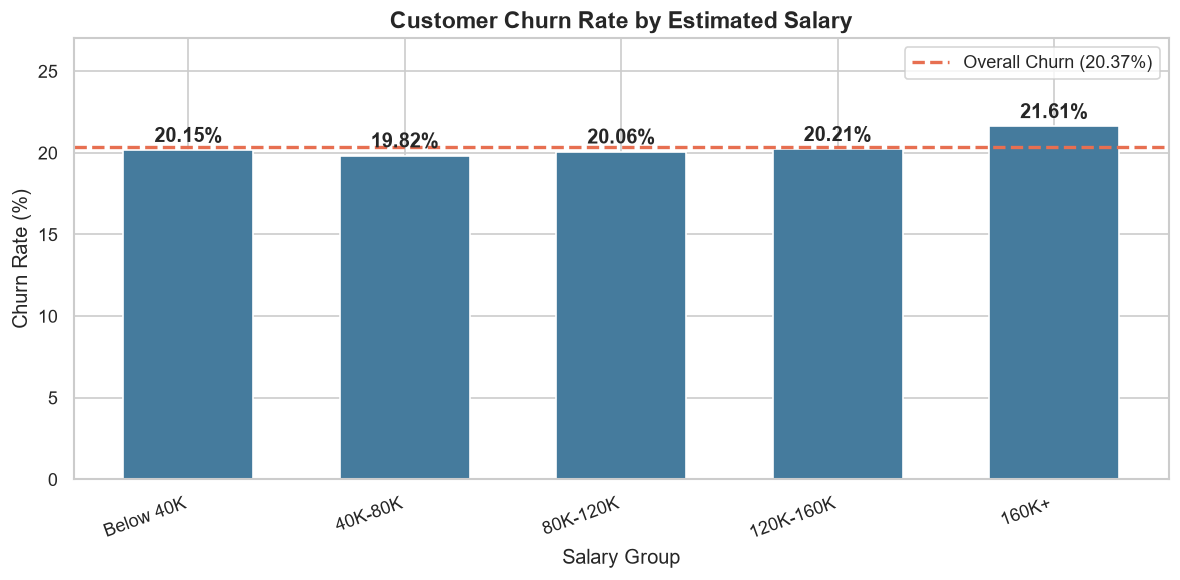

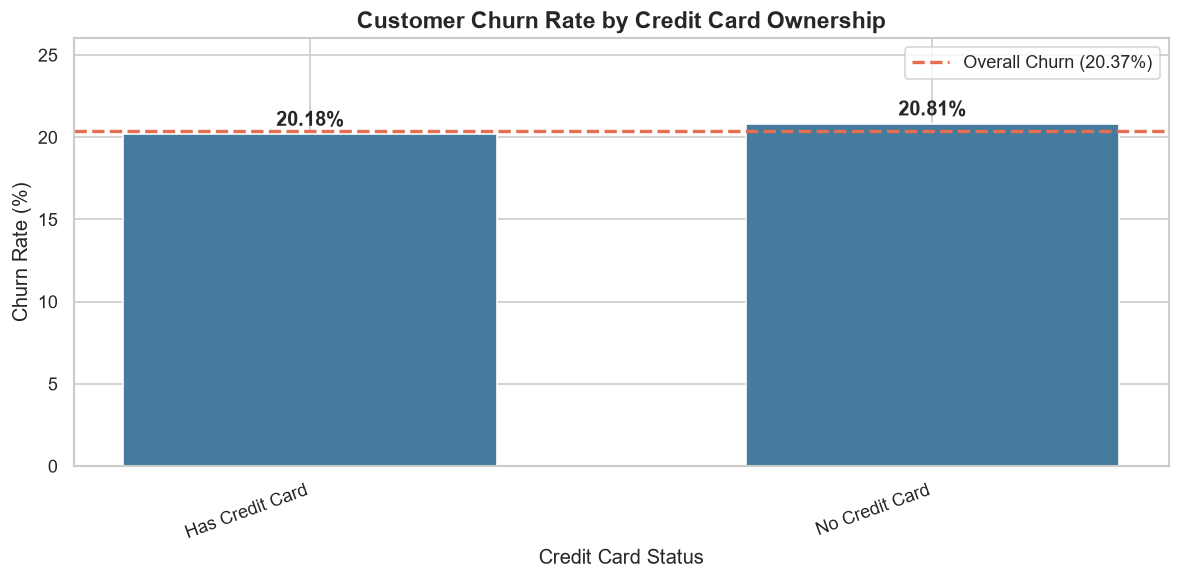

In [34]:
# ==================================================
# STEP 8.5: Generate Financial and Account Charts
# ==================================================

plot_segment_churn(
    balance_analysis,
    "balance_group",
    "Customer Churn Rate by Account Balance",
    "balance_group_churn_rate.png"
)

plot_segment_churn(
    credit_analysis,
    "credit_score_group",
    "Customer Churn Rate by Credit Score",
    "credit_score_churn_rate.png"
)

plot_segment_churn(
    tenure_analysis,
    "tenure_group",
    "Customer Churn Rate by Tenure",
    "tenure_churn_rate.png"
)

plot_segment_churn(
    salary_analysis,
    "salary_group",
    "Customer Churn Rate by Estimated Salary",
    "salary_churn_rate.png"
)

plot_segment_churn(
    card_analysis,
    "credit_card_status",
    "Customer Churn Rate by Credit Card Ownership",
    "credit_card_churn_rate.png"
)


### Financial and Account Characteristics — Business Findings

#### Key Findings

**Account Balance**
- Customers with zero account balance have a churn rate of 13.82%.
- Customers with balances between 100K and 150K have a churn rate of 25.77%.
- The below-50K group has a churn rate of 34.67%, but contains only 75 customers.

**Credit Score**
- Customers with credit scores below 500 have a churn rate of 23.73%.
- Customers with scores of 800+ have a churn rate of 19.54%.
- Churn rates across credit score groups are relatively close compared with differences observed for age or product ownership.

**Customer Tenure**
- Churn rates range from 18.87% to 21.30% across tenure groups.
- No strong or consistent pattern is apparent from these groups.

**Estimated Salary**
- Churn rates range from 19.82% to 21.61% across salary groups.
- Estimated salary shows relatively little variation in churn rates.

**Credit Card Ownership**
- Customers without a credit card have a churn rate of 20.81%.
- Customers with a credit card have a churn rate of 20.18%.
- The difference is small.

#### Business Insights
- Account balance shows more noticeable variation in churn rates than tenure, salary, or credit card ownership.
- Credit score exhibits relatively modest differences across groups.
- Small segments, such as customers with balances below 50K, require cautious interpretation.
- Financial characteristics should be evaluated alongside customer activity, product ownership, and geography.

#### Business Recommendations
- Further investigate churn among customers with balances between 100K and 150K.
- Examine whether activity or product ownership helps explain balance-related churn differences.
- Avoid using credit score, salary, or account balance alone to determine customer retention actions.
- Validate potential retention strategies through additional analysis and testing.


## 8. Correlation Analysis

### Business Questions
1. Which numerical customer characteristics are associated with churn?
2. Are any numerical features strongly correlated with one another?
3. Which relationships should be investigated further through customer segmentation?

### Objectives
- Calculate Pearson correlation coefficients.
- Visualize numerical relationships using a correlation heatmap.
- Rank numerical features by their correlation with churn.
- Interpret correlation strength and direction.

### Visualizations
1. Correlation matrix heatmap
2. Feature correlation with churn — Horizontal bar chart

### Interpretation Note
Correlation measures linear association, not causation.

Binary variables such as `exited` and `isactivemember` can be included in Pearson correlation analysis, but the results must be interpreted appropriately.


In [35]:
# ==================================================
# STEP 9.1: Calculate Pearson Correlation Matrix
# ==================================================

correlation_columns = [
    "creditscore",
    "age",
    "tenure",
    "balance",
    "numofproducts",
    "hascrcard",
    "isactivemember",
    "estimatedsalary",
    "exited"
]

correlation_matrix = df[correlation_columns].corr(
    method="pearson"
)

display(correlation_matrix.round(3))

,creditscore,age,tenure,balance,numofproducts,hascrcard,isactivemember,estimatedsalary,exited
creditscore,1.00,-0.00,0.00,0.01,0.01,-0.01,0.03,-0.00,-0.03
age,-0.00,1.00,-0.01,0.03,-0.03,-0.01,0.09,-0.01,0.28
tenure,0.00,-0.01,1.00,-0.01,0.01,0.02,-0.03,0.01,-0.01
balance,0.01,0.03,-0.01,1.00,-0.30,-0.01,-0.01,0.01,0.12
numofproducts,0.01,-0.03,0.01,-0.30,1.00,0.00,0.01,0.01,-0.05
hascrcard,-0.01,-0.01,0.02,-0.01,0.00,1.00,-0.01,-0.01,-0.01
isactivemember,0.03,0.09,-0.03,-0.01,0.01,-0.01,1.00,-0.01,-0.16
estimatedsalary,-0.00,-0.01,0.01,0.01,0.01,-0.01,-0.01,1.00,0.01
exited,-0.03,0.28,-0.01,0.12,-0.05,-0.01,-0.16,0.01,1.00


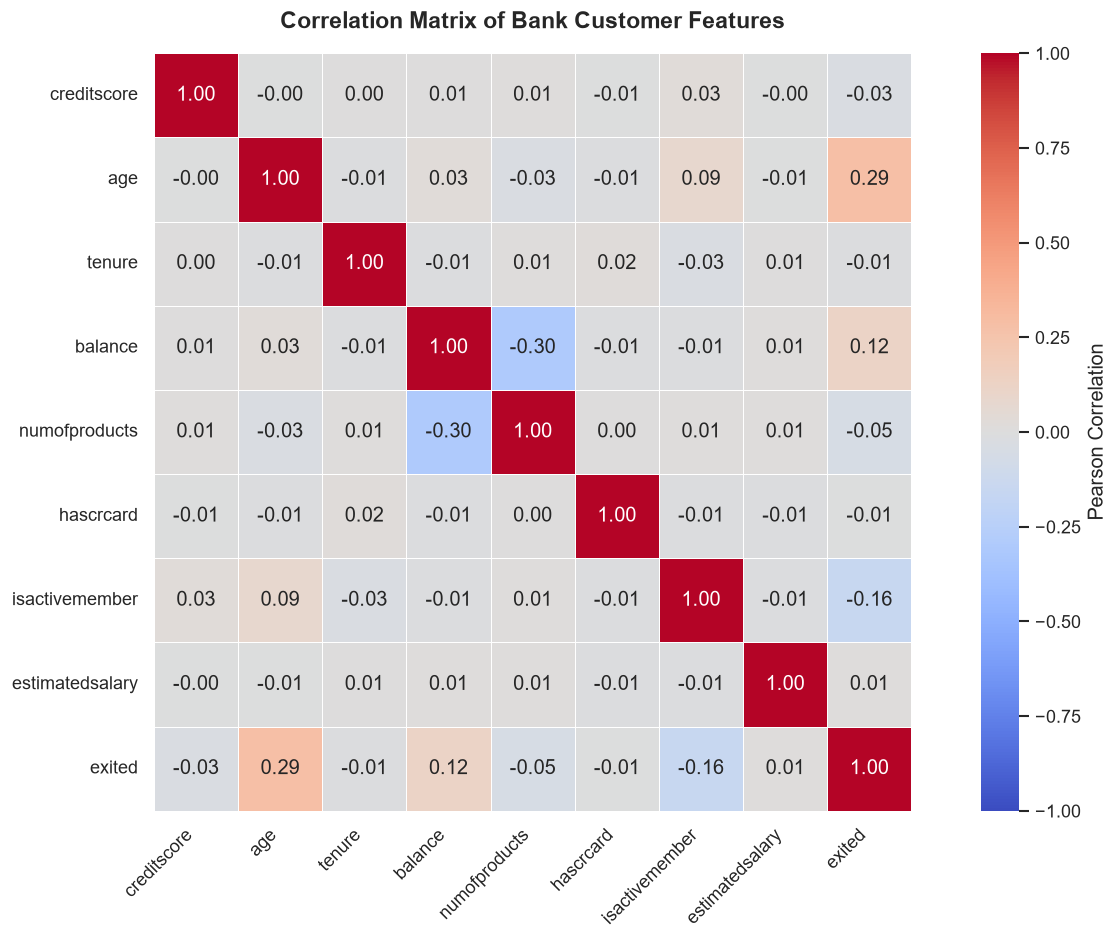

In [36]:
# ==================================================
# STEP 9.2: Correlation Matrix Heatmap
# ==================================================

fig, ax = plt.subplots(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Pearson Correlation"},
    ax=ax
)

ax.set_title(
    "Correlation Matrix of Bank Customer Features",
    fontsize=14,
    fontweight="bold",
    pad=15
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    output_dir / "customer_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Feature Correlation with Customer Churn

**Business Question:** Which numerical customer features have the strongest linear associations with churn?

We will extract correlations with `exited`, excluding its self-correlation.

- Positive correlation: Higher feature values tend to be associated with a higher churn indicator.
- Negative correlation: Higher feature values tend to be associated with a lower churn indicator.
- Correlation magnitude indicates the strength of the linear relationship.

These results will be used to guide further exploratory analysis, not to establish causes of churn.


In [38]:
# ==================================================
# STEP 9.3: Feature Correlation with Churn
# ==================================================

churn_correlations = (
    correlation_matrix["exited"]
    .drop("exited")
    .sort_values()
)

correlation_results = (
    churn_correlations
    .rename("correlation_with_churn")
    .reset_index()
    .rename(columns={"index": "feature"})
)

display(correlation_results.round(4))

,feature,correlation_with_churn
0,isactivemember,-0.16
1,numofproducts,-0.05
2,creditscore,-0.03
3,tenure,-0.01
4,hascrcard,-0.01
5,estimatedsalary,0.01
6,balance,0.12
7,age,0.29


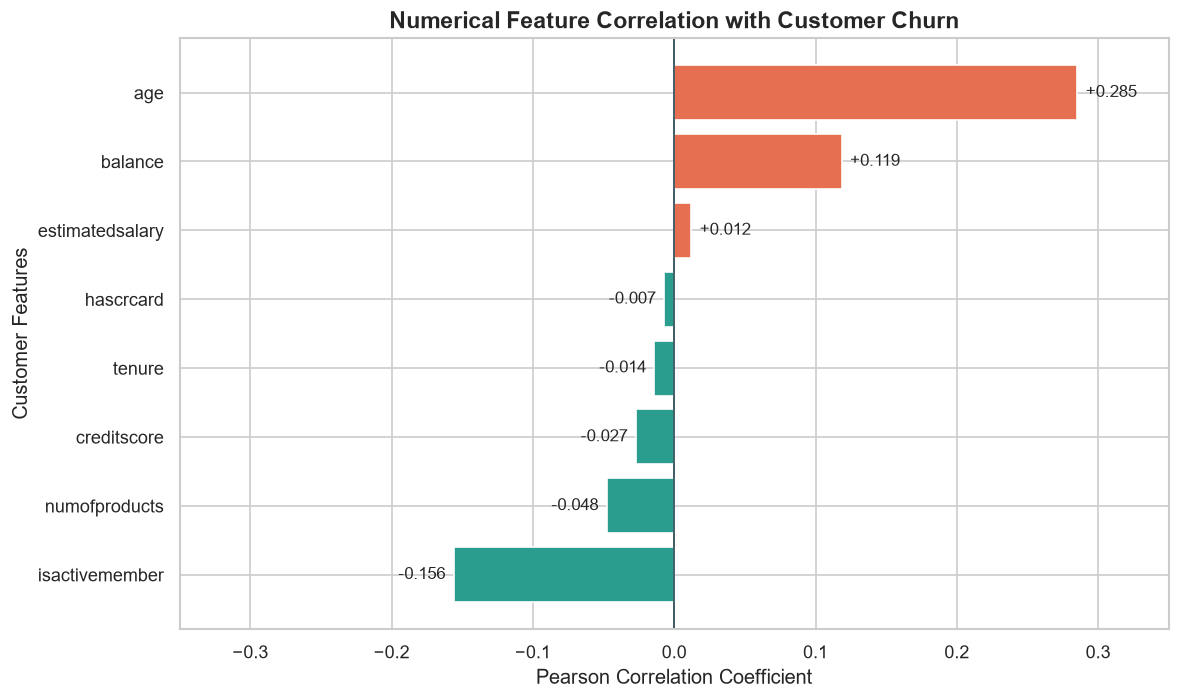

In [39]:
# ==================================================
# STEP 9.4: Feature Correlation Bar Chart
# ==================================================

fig, ax = plt.subplots(figsize=(10, 6))

colors = [
    "#E76F51" if value > 0 else "#2A9D8F"
    for value in churn_correlations.values
]

bars = ax.barh(
    churn_correlations.index,
    churn_correlations.values,
    color=colors
)

ax.axvline(
    x=0,
    color="#264653",
    linewidth=1
)

for bar in bars:
    width = bar.get_width()

    ax.annotate(
        f"{width:+.3f}",
        xy=(width, bar.get_y() + bar.get_height() / 2),
        xytext=(5 if width >= 0 else -5, 0),
        textcoords="offset points",
        ha="left" if width >= 0 else "right",
        va="center",
        fontsize=10
    )

ax.set_xlim(-0.35, 0.35)
ax.set_title(
    "Numerical Feature Correlation with Customer Churn",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Pearson Correlation Coefficient")
ax.set_ylabel("Customer Features")

plt.tight_layout()

plt.savefig(
    output_dir / "feature_correlation_with_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Correlation Analysis — Business Findings

#### Business Insights

- Identify numerical features with the strongest positive and negative correlations with churn.
- Compare these findings with earlier descriptive statistical analysis.
- Note that low Pearson correlation does not rule out non-linear or segment-specific relationships.

#### Business Recommendations

- Investigate the strongest observed associations using customer segmentation.
- Consider customer activity and product ownership alongside numerical characteristics.
- Avoid treating correlation as evidence of causation.

In [40]:
# Display feature correlations with customer churn
display(correlation_results.round(4))

,feature,correlation_with_churn
0,isactivemember,-0.16
1,numofproducts,-0.05
2,creditscore,-0.03
3,tenure,-0.01
4,hascrcard,-0.01
5,estimatedsalary,0.01
6,balance,0.12
7,age,0.29



### Correlation Analysis — Business Findings

#### Key Findings

1. **Customer Age**
   - Age has the highest positive correlation with churn (r = +0.29).
   - Higher age is associated with a higher churn indicator in the dataset.
   - Earlier age-group analysis also identified substantial differences in churn rates across age groups.

2. **Customer Activity**
   - Active membership has a negative correlation with churn (r = -0.16).
   - Active customers tend to have lower churn rates than inactive customers.
   - Earlier analysis showed churn rates of 14.27% for active customers and 26.85% for inactive customers.

3. **Account Balance**
   - Account balance has a weak positive correlation with churn (r = +0.12).
   - Customers with higher balances show a modest tendency toward higher churn in the linear analysis.
   - Segment-level analysis is needed because the relationship may not be uniform across balance ranges.

4. **Number of Products**
   - Product ownership has a very weak negative correlation with churn (r = -0.05).
   - However, earlier segment analysis revealed substantial differences in churn rates across product counts.
   - This indicates that Pearson correlation alone does not adequately describe the relationship.

5. **Other Variables**
   - Credit score: r = -0.03.
   - Tenure: r = -0.01.
   - Credit card ownership: r = -0.01.
   - Estimated salary: r = +0.01.
   - These variables show negligible or very weak linear correlations with churn.

#### Business Insights

- Age shows the strongest positive linear association with churn among the numerical variables analyzed.
- Customer activity shows the strongest negative association.
- Account balance shows a weaker positive association.
- Product ownership demonstrates why segment-level analysis is important even when overall linear correlation is low.
- Correlation does not establish causation or independently measure predictive performance.

#### Business Recommendations

- Investigate customer engagement and account activity patterns.
- Examine churn differences across balance and product ownership segments.
- Evaluate combinations of customer characteristics rather than relying on individual correlation coefficients.
- Use age-related findings to understand customer experience differences, not to automatically determine individual retention treatment.
- Validate proposed retention strategies through further analysis and controlled testing.


## 9. Multivariable Customer Segmentation

### 9.1 Geography × Customer Activity

#### Business Question
How does customer churn vary across countries when customer activity status is also considered?

#### Objectives
- Compare churn rates for active and inactive customers within each country.
- Identify geographical and activity combinations with elevated churn.
- Compare segment-level churn rates against the overall benchmark.
- Examine both customer counts and churn rates to support interpretation.

#### Visualization
- Geography × Customer Activity Churn Rate Heatmap

#### Overall Churn Benchmark
20.37%


In [41]:
# ==================================================
# STEP 10.1: Geography × Customer Activity Analysis
# ==================================================

geo_activity_analysis = (
    df.groupby(["geography", "isactivemember"])
    .agg(
        total_customers=("customerid", "count"),
        churned_customers=("exited", "sum")
    )
    .reset_index()
)

# Calculate churn rate
geo_activity_analysis["churn_rate"] = (
    geo_activity_analysis["churned_customers"]
    / geo_activity_analysis["total_customers"] * 100
)

# Convert activity codes to readable labels
geo_activity_analysis["activity_status"] = (
    geo_activity_analysis["isactivemember"]
    .map({0: "Inactive", 1: "Active"})
)

# Sort by churn rate
geo_activity_analysis = geo_activity_analysis.sort_values(
    "churn_rate",
    ascending=False
)

display(geo_activity_analysis.round(2))

,geography,isactivemember,total_customers,churned_customers,churn_rate,activity_status
2,Germany,0,1261,518,41.08,Inactive
3,Germany,1,1248,296,23.72,Active
4,Spain,0,1165,272,23.35,Inactive
0,France,0,2423,512,21.13,Inactive
1,France,1,2591,298,11.50,Active
5,Spain,1,1312,141,10.75,Active


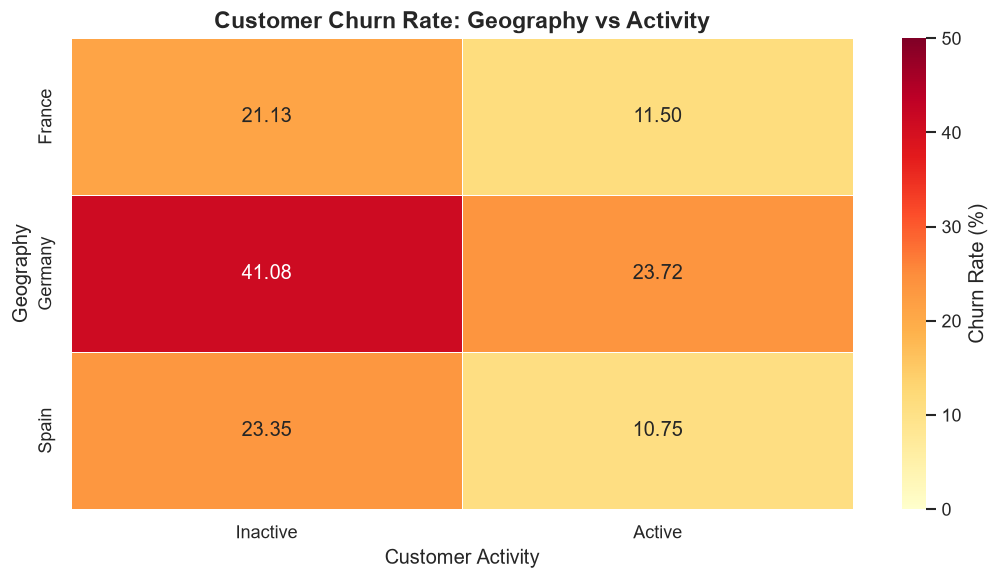

In [42]:
# ==================================================
# STEP 10.2: Geography × Activity Heatmap
# ==================================================

# Prepare heatmap data
geo_activity_heatmap = geo_activity_analysis.pivot(
    index="geography",
    columns="activity_status",
    values="churn_rate"
)

# Arrange columns consistently
geo_activity_heatmap = geo_activity_heatmap[
    ["Inactive", "Active"]
]

# Create visualization
fig, ax = plt.subplots(figsize=(9, 5))

sns.heatmap(
    geo_activity_heatmap,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    vmin=0,
    vmax=50,
    linewidths=0.5,
    cbar_kws={"label": "Churn Rate (%)"},
    ax=ax
)

ax.set_title(
    "Customer Churn Rate: Geography vs Activity",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Customer Activity")
ax.set_ylabel("Geography")

plt.tight_layout()

# Save PNG image
plt.savefig(
    output_dir / "geography_activity_churn_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Geography × Customer Activity — Business Findings

#### Key Findings

1. **Germany — Inactive Customers**
   - Total customers: 1,261.
   - Churned customers: 518.
   - Churn rate: 41.08%.
   - This is the highest churn rate among the six geography-activity combinations.

2. **Germany — Active Customers**
   - Churn rate: 23.72%.
   - This is also above the overall churn benchmark of 20.37%.

3. **Spain — Inactive Customers**
   - Churn rate: 23.35%.
   - Higher than Spain's active customer churn rate of 10.75%.

4. **France — Inactive Customers**
   - Churn rate: 21.13%.
   - Higher than France's active customer churn rate of 11.50%.

5. **Active Customers**
   - Spain has the lowest active customer churn rate at 10.75%.
   - France follows at 11.50%.
   - Germany has the highest active customer churn rate at 23.72%.

#### Business Insights

- Inactive customers show higher churn rates than active customers in all three countries.
- Germany's inactive customers represent a particularly important segment, with both a high churn rate and substantial churn volume.
- Germany's active customers also have a churn rate above the overall benchmark.
- Geography and activity together reveal differences that are less visible when each variable is analyzed independently.

#### Business Recommendations

- Investigate engagement patterns and customer experience among inactive customers in Germany.
- Compare customer product ownership and account characteristics across countries.
- Examine why active customers in Germany also show relatively elevated churn.
- Validate potential retention interventions before implementation.


### 9.2 Geography × Product Ownership

#### Business Question
How does customer churn vary by banking product ownership across France, Germany, and Spain?

#### Objectives
- Compare churn rates for customers owning 1, 2, 3, or 4 products in each country.
- Identify combinations with elevated churn rates.
- Evaluate customer counts and churn volumes alongside churn percentages.
- Compare segment-level churn rates against the overall benchmark of 20.37%.

#### Visualization
- Geography × Product Ownership Churn Rate Heatmap

#### Important Consideration
Small customer segments can produce extreme churn rates. Segment size must be considered before interpreting results.


In [43]:
# ==================================================
# STEP 10.2: Geography × Product Ownership Analysis
# ==================================================

geo_product_analysis = (
    df.groupby(["geography", "numofproducts"])
    .agg(
        total_customers=("customerid", "count"),
        churned_customers=("exited", "sum")
    )
    .reset_index()
)

# Calculate retained customers
geo_product_analysis["retained_customers"] = (
    geo_product_analysis["total_customers"]
    - geo_product_analysis["churned_customers"]
)

# Calculate churn rate
geo_product_analysis["churn_rate"] = (
    geo_product_analysis["churned_customers"]
    / geo_product_analysis["total_customers"] * 100
)

# Sort by country and product count
geo_product_analysis = geo_product_analysis.sort_values(
    ["geography", "numofproducts"]
)

display(geo_product_analysis.round(2))

,geography,numofproducts,total_customers,churned_customers,retained_customers,churn_rate
0,France,1,2514,564,1950,22.43
1,France,2,2367,135,2232,5.70
2,France,3,104,82,22,78.85
3,France,4,29,29,0,100.00
4,Germany,1,1349,578,771,42.85
5,Germany,2,1040,126,914,12.12
6,Germany,3,96,86,10,89.58
7,Germany,4,24,24,0,100.00
8,Spain,1,1221,267,954,21.87
9,Spain,2,1183,87,1096,7.35


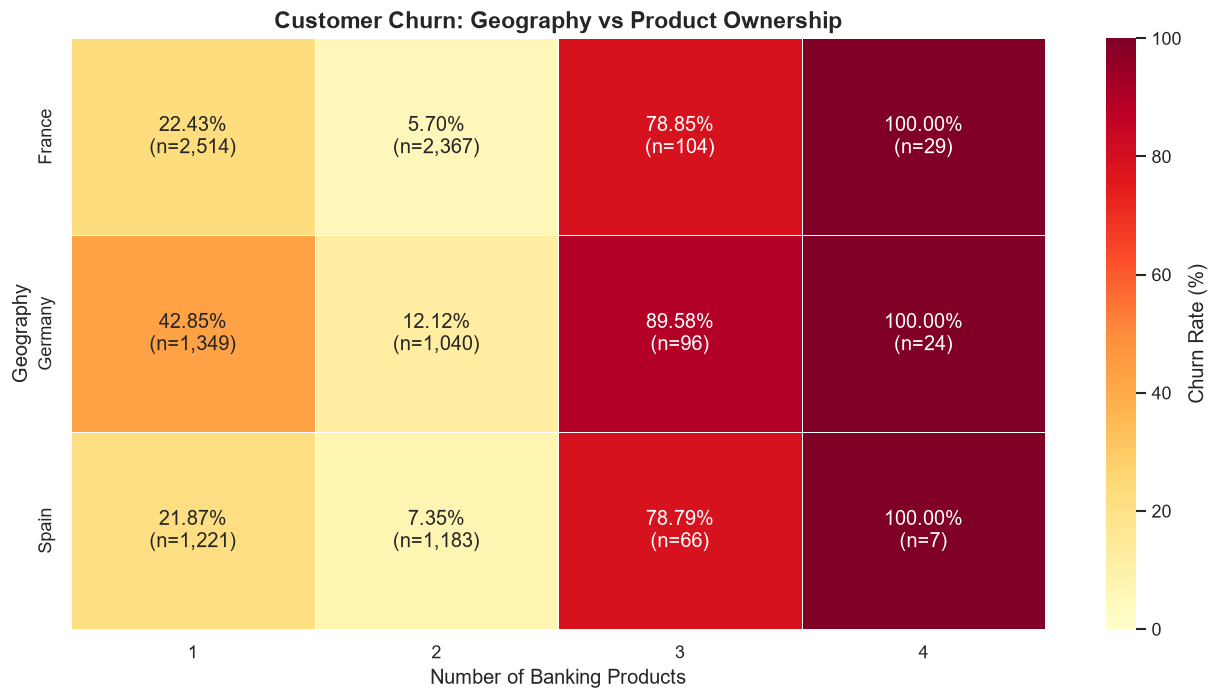

In [44]:
# ==================================================
# STEP 10.2: Geography × Products Churn Heatmap
# ==================================================

# Pivot churn rates
geo_product_heatmap = geo_product_analysis.pivot(
    index="geography",
    columns="numofproducts",
    values="churn_rate"
)

# Pivot customer counts
geo_product_counts = geo_product_analysis.pivot(
    index="geography",
    columns="numofproducts",
    values="total_customers"
)

# Create annotations: churn rate + segment size
annotations = geo_product_heatmap.copy().astype(object)

for country in geo_product_heatmap.index:
    for products in geo_product_heatmap.columns:
        rate = geo_product_heatmap.loc[country, products]
        count = geo_product_counts.loc[country, products]

        annotations.loc[country, products] = (
            f"{rate:.2f}%\n(n={count:,.0f})"
        )

# Create heatmap
fig, ax = plt.subplots(figsize=(11, 6))

sns.heatmap(
    geo_product_heatmap,
    annot=annotations,
    fmt="",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Churn Rate (%)"},
    ax=ax
)

ax.set_title(
    "Customer Churn: Geography vs Product Ownership",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Number of Banking Products")
ax.set_ylabel("Geography")

plt.tight_layout()

# Save image
plt.savefig(
    output_dir / "geography_product_churn_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Geography × Product Ownership — Business Findings

#### Key Findings

**Single-Product Customers**
- Germany has the highest churn rate at 42.85% (578 out of 1,349).
- France has a churn rate of 22.43% (564 out of 2,514).
- Spain has a churn rate of 21.87% (267 out of 1,221).

**Two-Product Customers**
- Germany has a churn rate of 12.12%.
- Spain has a churn rate of 7.35%.
- France has the lowest churn rate at 5.70%.

**Three- and Four-Product Customers**
- Earlier analysis identified high churn rates among customers owning three or four products.
- These groups have relatively small customer counts.
- Their country-level results require careful interpretation.

#### Business Insights

- Single-product customers have higher churn rates than two-product customers in all three countries.
- Germany's single-product customers show particularly elevated churn.
- France has a large volume of churned single-product customers despite a lower churn rate than Germany.
- Two-product customers consistently show lower churn rates across the three countries.
- Product ownership and geography together reveal useful patterns for further investigation.

#### Business Recommendations

- Investigate the customer experience of single-product customers, particularly in Germany.
- Examine customer activity among single-product customers to identify additional patterns.
- Study the characteristics of two-product customers without assuming product ownership directly prevents churn.
- Review small three- and four-product segments separately before drawing conclusions.


### 9.3 Age Group × Customer Activity

#### Business Question
How does customer churn vary across age groups when customer activity status is also considered?

#### Objectives
- Compare churn rates between active and inactive customers within each age group.
- Identify segments with elevated churn rates and substantial churn volumes.
- Compare segment churn rates against the overall benchmark of 20.37%.
- Consider customer counts when interpreting high churn percentages.

#### Visualization
- Age Group × Customer Activity Churn Rate Heatmap

#### Important Consideration
Age-related findings are descriptive and should not be used alone to determine individual customer treatment.


In [45]:
# ==================================================
# STEP 10.3: Age Group × Customer Activity Analysis
# ==================================================

age_activity_analysis = (
    df.groupby(
        ["age_group", "isactivemember"],
        observed=True
    )
    .agg(
        total_customers=("customerid", "count"),
        churned_customers=("exited", "sum")
    )
    .reset_index()
)

# Calculate retained customers
age_activity_analysis["retained_customers"] = (
    age_activity_analysis["total_customers"]
    - age_activity_analysis["churned_customers"]
)

# Calculate churn rate
age_activity_analysis["churn_rate"] = (
    age_activity_analysis["churned_customers"]
    / age_activity_analysis["total_customers"] * 100
)

# Convert activity codes into readable labels
age_activity_analysis["activity_status"] = (
    age_activity_analysis["isactivemember"]
    .map({0: "Inactive", 1: "Active"})
)

# Display results
display(age_activity_analysis.round(2))

,age_group,isactivemember,total_customers,churned_customers,retained_customers,churn_rate,activity_status
0,18-30,0,962,97,865,10.08,Inactive
1,18-30,1,1006,51,955,5.07,Active
2,31-40,0,2236,334,1902,14.94,Inactive
3,31-40,1,2215,204,2011,9.21,Active
4,41-50,0,1226,510,716,41.60,Inactive
5,41-50,1,1094,278,816,25.41,Active
6,51-60,0,336,288,48,85.71,Inactive
7,51-60,1,461,160,301,34.71,Active
8,61+,0,89,73,16,82.02,Inactive
9,61+,1,375,42,333,11.20,Active


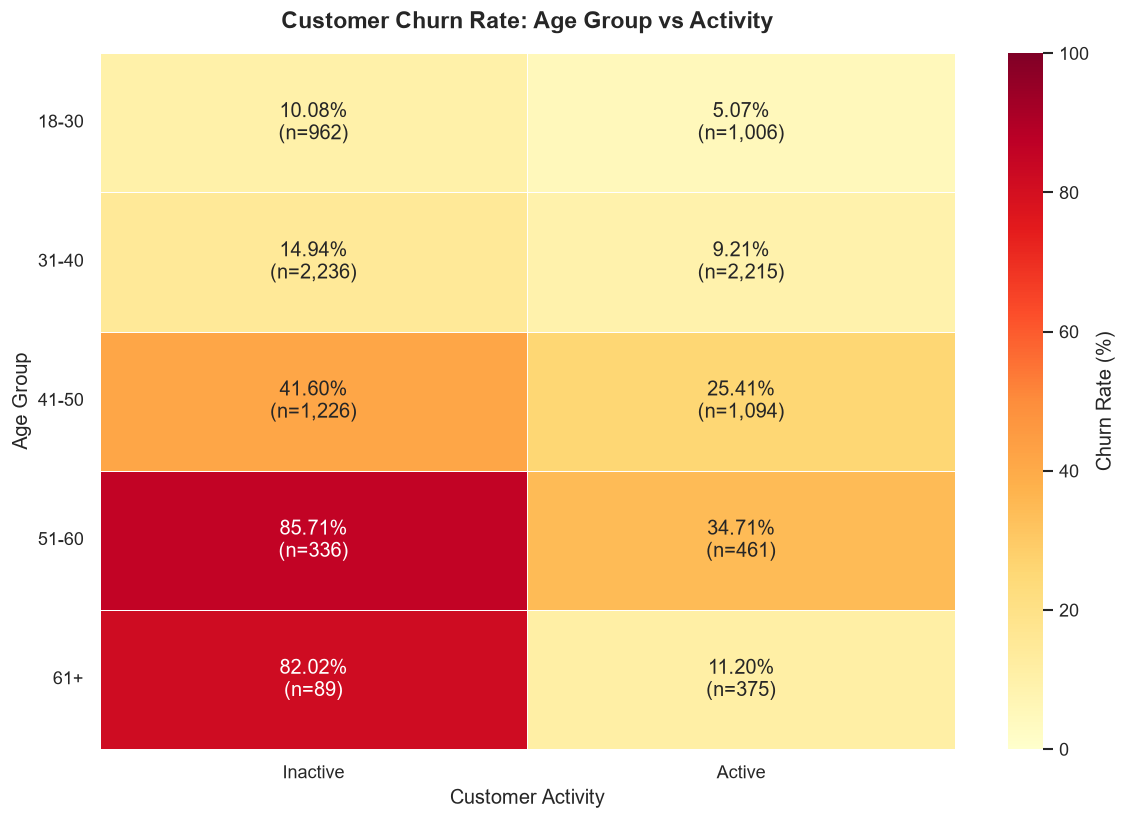

In [46]:
# ==================================================
# STEP 10.3: Age Group × Activity Churn Heatmap
# ==================================================

# Prepare churn rate matrix
age_activity_heatmap = age_activity_analysis.pivot(
    index="age_group",
    columns="activity_status",
    values="churn_rate"
)

# Prepare customer count matrix
age_activity_counts = age_activity_analysis.pivot(
    index="age_group",
    columns="activity_status",
    values="total_customers"
)

# Set consistent activity order
activity_order = ["Inactive", "Active"]

age_activity_heatmap = age_activity_heatmap[activity_order]
age_activity_counts = age_activity_counts[activity_order]

# Create annotations containing rate and count
annotations = age_activity_heatmap.copy().astype(object)

for age in age_activity_heatmap.index:
    for activity in activity_order:
        rate = age_activity_heatmap.loc[age, activity]
        count = age_activity_counts.loc[age, activity]

        annotations.loc[age, activity] = (
            f"{rate:.2f}%\n(n={count:,.0f})"
        )

# Create heatmap
fig, ax = plt.subplots(figsize=(10, 7))

sns.heatmap(
    age_activity_heatmap,
    annot=annotations,
    fmt="",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Churn Rate (%)"},
    ax=ax
)

ax.set_title(
    "Customer Churn Rate: Age Group vs Activity",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Customer Activity")
ax.set_ylabel("Age Group")

plt.yticks(rotation=0)
plt.tight_layout()

# Save visualization
plt.savefig(
    output_dir / "age_activity_churn_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Age Group × Customer Activity — Business Findings

#### Key Findings

**Customers Aged 18–30**
- Inactive churn rate: 10.08%.
- Active churn rate: 5.07%.
- Both groups are below the overall churn benchmark.

**Customers Aged 31–40**
- Inactive churn rate: 14.94%.
- Active churn rate: 9.21%.
- Inactive customers have higher churn rates.

**Customers Aged 41–50**
- Inactive churn rate: 41.60%, with 510 churned customers.
- Active churn rate: 25.41%, with 278 churned customers.
- This age group contributes substantial churn volume.

**Customers Aged 51–60**
- Inactive churn rate: 85.71%, with 288 churned customers.
- Active churn rate: 34.71%.
- This group shows the highest inactive churn rate.

**Customers Aged 61+**
- Inactive churn rate: 82.02%, with 73 churned customers.
- Active churn rate: 11.20%.
- The inactive segment contains only 89 customers, so its high churn rate requires cautious interpretation.

#### Business Insights

- Inactive customers have higher churn rates than active customers in every age group.
- The difference between active and inactive customers is particularly large in the 51–60 and 61+ groups.
- The inactive 41–50 segment has the highest churn volume among these age-activity combinations, with 510 churned customers.
- Churn rate and churn volume should both be considered when evaluating customer segments.

#### Business Recommendations

- Investigate customer engagement and service experience across age groups.
- Examine why inactivity is associated with particularly high churn in some age segments.
- Consider churn volume, segment size, and customer needs when prioritizing further investigation.
- Avoid using age alone to determine individual retention treatment.
- Validate potential interventions through additional analysis and testing.


### 9.4 Geography × Customer Activity × Product Ownership

#### Business Question
Which combinations of geography, customer activity, and banking product ownership contribute most to customer churn?

#### Objectives
- Analyze churn across three customer characteristics.
- Calculate customer counts, churn volumes, and churn rates.
- Identify segments contributing the largest number of churned customers.
- Distinguish high churn rates from high churn volumes.
- Identify customer segments requiring further investigation.

#### Visualizations
1. Top 10 Customer Segments by Churn Volume
2. Geography × Activity × Product Ownership Churn Heatmap

#### Overall Churn Benchmark
20.37%

#### Important Consideration
Small customer segments may have extreme churn rates. Customer counts must be considered when interpreting results.


In [47]:
# ==================================================
# STEP 10.4.1: Three-Dimensional Customer Segmentation
# ==================================================

geo_activity_product_analysis = (
    df.groupby(
        ["geography", "isactivemember", "numofproducts"]
    )
    .agg(
        total_customers=("customerid", "count"),
        churned_customers=("exited", "sum")
    )
    .reset_index()
)

# Calculate retained customers
geo_activity_product_analysis["retained_customers"] = (
    geo_activity_product_analysis["total_customers"]
    - geo_activity_product_analysis["churned_customers"]
)

# Calculate churn rate
geo_activity_product_analysis["churn_rate"] = (
    geo_activity_product_analysis["churned_customers"]
    / geo_activity_product_analysis["total_customers"] * 100
)

# Contribution to total customer churn
geo_activity_product_analysis["churn_contribution_pct"] = (
    geo_activity_product_analysis["churned_customers"]
    / churned_customers * 100
)

# Convert activity codes to labels
geo_activity_product_analysis["activity_status"] = (
    geo_activity_product_analysis["isactivemember"]
    .map({0: "Inactive", 1: "Active"})
)

# Create readable segment labels
geo_activity_product_analysis["segment"] = (
    geo_activity_product_analysis["geography"]
    + " | "
    + geo_activity_product_analysis["activity_status"]
    + " | "
    + geo_activity_product_analysis["numofproducts"].astype(str)
    + " Product(s)"
)

# Sort by churn volume
geo_activity_product_analysis = (
    geo_activity_product_analysis
    .sort_values("churned_customers", ascending=False)
)

display(geo_activity_product_analysis.round(2))

,geography,isactivemember,numofproducts,total_customers,churned_customers,retained_customers,churn_rate,churn_contribution_pct,activity_status,segment
8,Germany,0,1,720,375,345,52.08,18.41,Inactive,Germany | Inactive | 1 Product(s)
0,France,0,1,1253,371,882,29.61,18.21,Inactive,France | Inactive | 1 Product(s)
12,Germany,1,1,629,203,426,32.27,9.97,Active,Germany | Active | 1 Product(s)
4,France,1,1,1261,193,1068,15.31,9.47,Active,France | Active | 1 Product(s)
16,Spain,0,1,548,178,370,32.48,8.74,Inactive,Spain | Inactive | 1 Product(s)
20,Spain,1,1,673,89,584,13.22,4.37,Active,Spain | Active | 1 Product(s)
9,Germany,0,2,472,78,394,16.53,3.83,Inactive,Germany | Inactive | 2 Product(s)
1,France,0,2,1098,77,1021,7.01,3.78,Inactive,France | Inactive | 2 Product(s)
5,France,1,2,1269,58,1211,4.57,2.85,Active,France | Active | 2 Product(s)
17,Spain,0,2,574,57,517,9.93,2.80,Inactive,Spain | Inactive | 2 Product(s)


In [49]:
# ==================================================
# STEP 10.4.2: Top 10 Segments by Churn Volume
# ==================================================

top_10_segments = (
    geo_activity_product_analysis
    .nlargest(10, "churned_customers")
    .copy()
)

display(
    top_10_segments[
        [
            "segment",
            "total_customers",
            "churned_customers",
            "churn_rate",
            "churn_contribution_pct"
        ]
    ].round(2)
)

# Validate total churn contribution
top_10_churn = top_10_segments["churned_customers"].sum()

print(f"Top 10 Churned Customers: {top_10_churn:,}")
print(
    f"Contribution to Overall Churn: "
    f"{top_10_churn / churned_customers * 100:.2f}%"
)

,segment,total_customers,churned_customers,churn_rate,churn_contribution_pct
8,Germany | Inactive | 1 Product(s),720,375,52.08,18.41
0,France | Inactive | 1 Product(s),1253,371,29.61,18.21
12,Germany | Active | 1 Product(s),629,203,32.27,9.97
4,France | Active | 1 Product(s),1261,193,15.31,9.47
16,Spain | Inactive | 1 Product(s),548,178,32.48,8.74
20,Spain | Active | 1 Product(s),673,89,13.22,4.37
9,Germany | Inactive | 2 Product(s),472,78,16.53,3.83
1,France | Inactive | 2 Product(s),1098,77,7.01,3.78
5,France | Active | 2 Product(s),1269,58,4.57,2.85
17,Spain | Inactive | 2 Product(s),574,57,9.93,2.80


Top 10 Churned Customers: 1,679
Contribution to Overall Churn: 82.43%


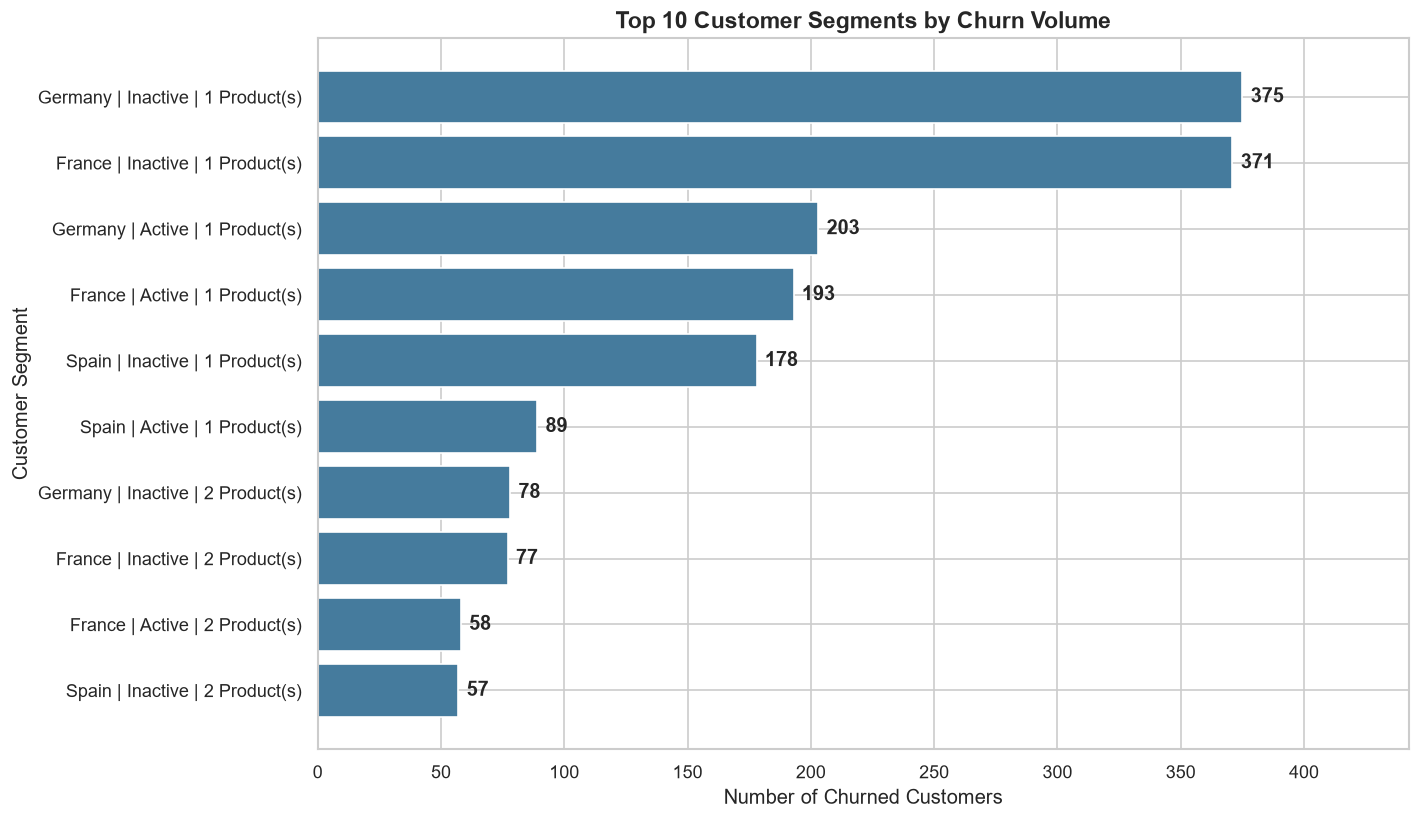

In [50]:
# ==================================================
# STEP 10.4.3: Top 10 Segments by Churn Volume Chart
# ==================================================

chart_data = top_10_segments.sort_values(
    "churned_customers",
    ascending=True
)

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    chart_data["segment"],
    chart_data["churned_customers"],
    color="#457B9D"
)

for bar in bars:
    width = bar.get_width()

    ax.annotate(
        f"{width:,.0f}",
        xy=(width, bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        fontweight="bold"
    )

ax.set_title(
    "Top 10 Customer Segments by Churn Volume",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Number of Churned Customers")
ax.set_ylabel("Customer Segment")
ax.set_xlim(0, chart_data["churned_customers"].max() * 1.18)

plt.tight_layout()

plt.savefig(
    output_dir / "top_10_churn_segments.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

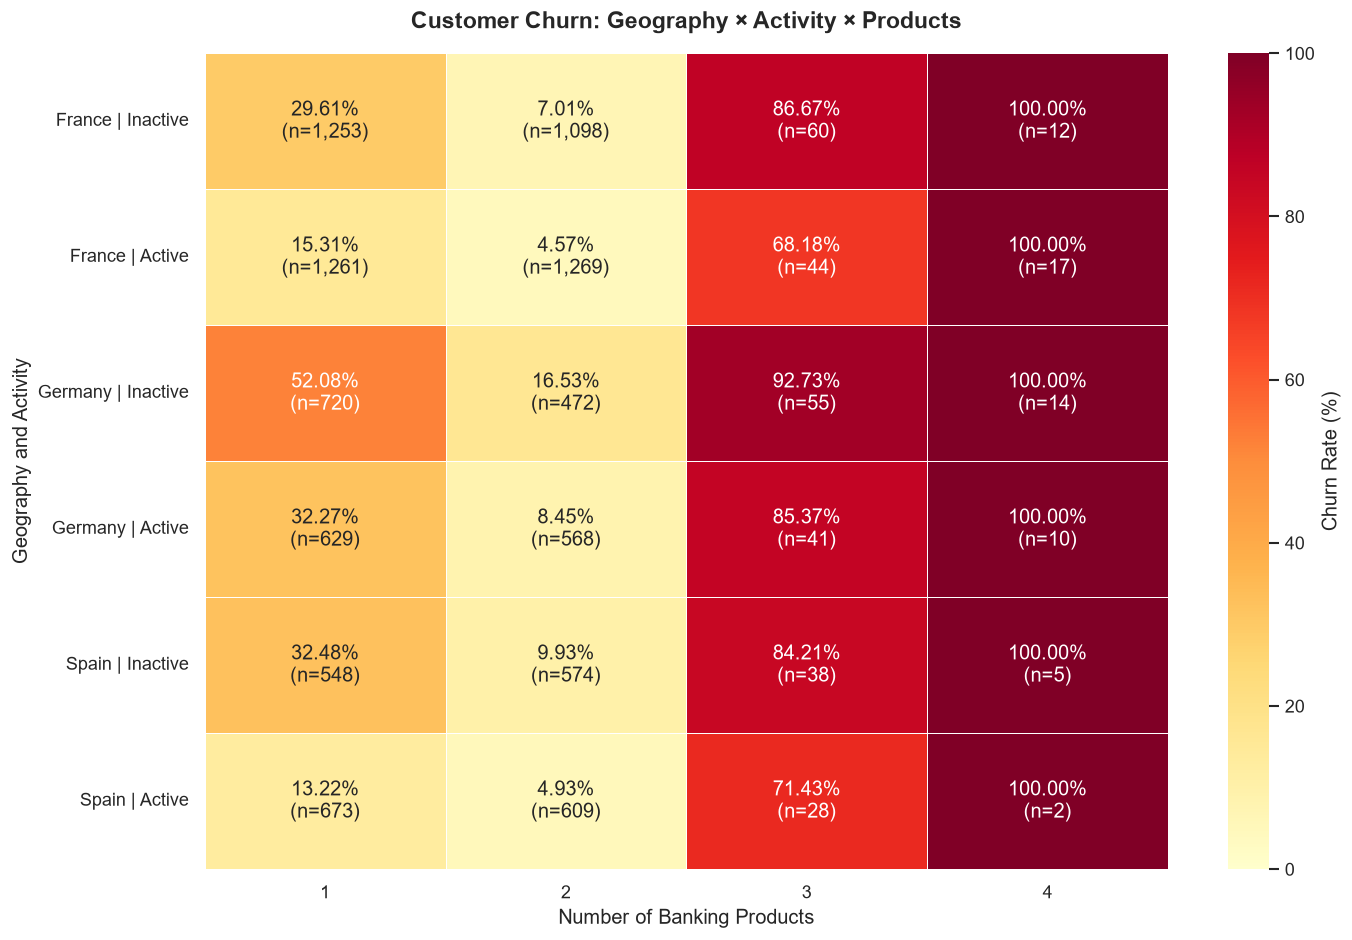

In [51]:
# ==================================================
# STEP 10.4.4: Geography × Activity × Products Heatmap
# ==================================================

heatmap_source = geo_activity_product_analysis.copy()

heatmap_source["geo_activity"] = (
    heatmap_source["geography"]
    + " | "
    + heatmap_source["activity_status"]
)

# Pivot churn rates
segment_rate_matrix = heatmap_source.pivot(
    index="geo_activity",
    columns="numofproducts",
    values="churn_rate"
)

# Pivot customer counts
segment_count_matrix = heatmap_source.pivot(
    index="geo_activity",
    columns="numofproducts",
    values="total_customers"
)

# Set readable row order
row_order = [
    "France | Inactive",
    "France | Active",
    "Germany | Inactive",
    "Germany | Active",
    "Spain | Inactive",
    "Spain | Active"
]

segment_rate_matrix = segment_rate_matrix.reindex(row_order)
segment_count_matrix = segment_count_matrix.reindex(row_order)

# Create rate and count annotations
annotations = segment_rate_matrix.copy().astype(object)

for segment in segment_rate_matrix.index:
    for products in segment_rate_matrix.columns:
        rate = segment_rate_matrix.loc[segment, products]
        count = segment_count_matrix.loc[segment, products]

        if pd.notna(rate):
            annotations.loc[segment, products] = (
                f"{rate:.2f}%\n(n={count:,.0f})"
            )
        else:
            annotations.loc[segment, products] = ""

# Create heatmap
fig, ax = plt.subplots(figsize=(12, 8))

sns.heatmap(
    segment_rate_matrix,
    annot=annotations,
    fmt="",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Churn Rate (%)"},
    ax=ax
)

ax.set_title(
    "Customer Churn: Geography × Activity × Products",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Number of Banking Products")
ax.set_ylabel("Geography and Activity")

plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    output_dir / "geography_activity_product_churn_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Geography × Activity × Product Ownership — Business Findings

#### Key Findings

1. **Germany — Inactive — 1 Product**
   - Total customers: 720.
   - Churned customers: 375.
   - Churn rate: 52.08%.
   - Contribution to total churn: 18.41%.

2. **France — Inactive — 1 Product**
   - Total customers: 1,253.
   - Churned customers: 371.
   - Churn rate: 29.61%.
   - Contribution to total churn: 18.21%.

3. **Germany — Active — 1 Product**
   - Churned customers: 203.
   - Churn rate: 32.27%.
   - Contribution to total churn: 9.97%.

4. **France — Active — 1 Product**
   - Churned customers: 193.
   - Churn rate: 15.31%.
   - Contribution to total churn: 9.47%.

5. **Spain — Inactive — 1 Product**
   - Churned customers: 178.
   - Churn rate: 32.48%.
   - Contribution to total churn: 8.74%.

6. **Top Five Segments**
   - Combined churned customers: 1,320.
   - Combined contribution to total churn: 64.80%.
   - All five segments contain customers owning one banking product.

#### Business Insights

- Single-product customers account for a substantial proportion of churn across the leading segments.
- Inactive, single-product customers in Germany and France together contribute approximately 36.62% of all churned customers.
- Germany's inactive single-product segment has both a high churn rate and a substantial churn volume.
- Some segments with very high churn percentages contain relatively few customers.
- Segment-level churn rates and churn contributions provide complementary information for retention analysis.

#### Business Recommendations

- Investigate the banking experience and engagement patterns of inactive, single-product customers.
- Examine Germany's single-product customer segments in greater detail.
- Evaluate customer feedback, service issues, and product suitability before recommending retention interventions.
- Prioritize further investigation using churn volume, segment size, and business impact.
- Validate potential retention strategies through controlled testing.


In [52]:
# ==================================================
# STEP 11.1: Final Dataset and EDA Validation
# ==================================================

original_columns = [
    "customerid", "surname", "creditscore",
    "geography", "gender", "age", "tenure",
    "balance", "numofproducts", "hascrcard",
    "isactivemember", "estimatedsalary", "exited"
]

validation_results = {
    "Total Customers": len(df),
    "Unique Customer IDs": df["customerid"].nunique(),
    "Duplicate Customer IDs": df["customerid"].duplicated().sum(),
    "Missing Values": df[original_columns].isnull().sum().sum(),
    "Churned Customers": int(df["exited"].sum()),
    "Retained Customers": int((df["exited"] == 0).sum()),
    "Churn Rate (%)": round(df["exited"].mean() * 100, 2),
    "Retention Rate (%)": round((1 - df["exited"].mean()) * 100, 2)
}

validation_df = pd.DataFrame(
    validation_results.items(),
    columns=["Validation Check", "Result"]
)

display(validation_df)

# Validate segmentation totals
assert geo_activity_product_analysis["total_customers"].sum() == len(df)
assert geo_activity_product_analysis["churned_customers"].sum() == churned_customers

print("Segmentation totals validated successfully!")

,Validation Check,Result
0,Total Customers,10000.00
1,Unique Customer IDs,10000.00
2,Duplicate Customer IDs,0.00
3,Missing Values,0.00
4,Churned Customers,2037.00
5,Retained Customers,7963.00
6,Churn Rate (%),20.37
7,Retention Rate (%),79.63


Segmentation totals validated successfully!



### Final EDA Validation Summary

#### Data Quality
- The dataset contains 10,000 customer records.
- All customer IDs are unique.
- No missing values remain in the original analytical columns.
- The churn target contains 2,037 churned and 7,963 retained customers.

#### Analysis Validation
- Overall churn rate: 20.37%.
- Overall retention rate: 79.63%.
- Multivariable customer segments reconcile with the complete dataset.
- Statistical analysis, correlation analysis, and customer segmentation have been completed.

#### Business Insights
- Age and customer activity show notable associations with churn.
- Germany has the highest country-level churn rate.
- Product ownership shows substantial differences in churn across customer segments.
- Inactive, single-product customers in Germany and France contribute a significant share of total churn.